In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() == 'project.zip':
            print(os.path.join(root, file))

/content/drive/MyDrive/Project.zip


In [13]:
import zipfile

zip_path = '/content/drive/MyDrive/Project.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for file in zip_ref.namelist():
        print(file)

MedTourEasy_Patient_Conversion_Intelligence.pdf
communication_logs.csv
country_reference.csv
data_dictionary.csv
mte_patient_intelligence.db
patient_journey.csv
provider_master.csv
treatment_outcomes.csv


In [14]:
import pandas as pd
import zipfile

zip_path = '/content/drive/MyDrive/Project.zip'

with zipfile.ZipFile(zip_path, 'r') as z:
    with z.open('data_dictionary.csv') as file:
        dictionary = pd.read_csv(file)

print("Rows and columns:", dictionary.shape)
display(dictionary.head(15))

Rows and columns: (67, 4)


,file_name,field_name,description,example_value
0,patient_journey.csv,patient_id,"Patient funnel, lead, response, conversion, dr...",MTE-PAT-00001
1,patient_journey.csv,inquiry_date,"Patient funnel, lead, response, conversion, dr...",2025-11-12 18:00:00
2,patient_journey.csv,country,"Patient funnel, lead, response, conversion, dr...",Thailand
3,patient_journey.csv,age_group,"Patient funnel, lead, response, conversion, dr...",40-49
4,patient_journey.csv,gender,"Patient funnel, lead, response, conversion, dr...",Other/Not shared
5,patient_journey.csv,treatment_category,"Patient funnel, lead, response, conversion, dr...",Oncology
6,patient_journey.csv,provider_id,"Patient funnel, lead, response, conversion, dr...",PVD-022
7,patient_journey.csv,lead_source,"Patient funnel, lead, response, conversion, dr...",Phone
8,patient_journey.csv,coordinator_id,"Patient funnel, lead, response, conversion, dr...",COORD-08
9,patient_journey.csv,budget_band,"Patient funnel, lead, response, conversion, dr...",Low


In [15]:
import pandas as pd
import zipfile

with zipfile.ZipFile('/content/drive/MyDrive/Project.zip') as z:
    with z.open('patient_journey.csv') as file:
        patients = pd.read_csv(file)

display(patients.head())

,patient_id,inquiry_date,country,age_group,gender,treatment_category,provider_id,lead_source,coordinator_id,budget_band,...,treatment_completed,follow_up_completed,current_stage,drop_off_flag,drop_off_stage,reason_for_drop_off,estimated_case_value_inr,actual_revenue_inr,service_cost_inr,satisfaction_score
0,MTE-PAT-00001,2025-11-12 18:00:00,Thailand,40-49,Other/Not shared,Oncology,PVD-022,Phone,COORD-08,Low,...,0,0,First Response,0,NaN,NaN,780855,0,0,NaN
1,MTE-PAT-00002,2025-04-12 04:00:00,Kenya,60+,Female,Fertility,PVD-022,WhatsApp,COORD-13,High,...,1,1,Follow-up,0,NaN,NaN,270529,270529,161988,7.7
2,MTE-PAT-00003,2025-12-28 06:00:00,Tanzania,50-59,Male,Oncology,PVD-008,Web Form,COORD-01,High,...,1,0,Treatment Completed,0,NaN,NaN,549181,549181,312857,7.4
3,MTE-PAT-00004,2025-08-31 21:00:00,Oman,40-49,Other/Not shared,Oncology,PVD-005,Phone,COORD-15,High,...,0,0,Consultation,1,Inquiry,Response delay,505922,0,0,NaN
4,MTE-PAT-00005,2025-08-26 18:00:00,Nepal,50-59,Male,Fertility,PVD-009,Phone,COORD-09,Low,...,0,0,First Response,0,NaN,NaN,631722,0,0,NaN


In [6]:
patients.dtypes

,0
patient_id,object
inquiry_date,object
country,object
age_group,object
gender,object
treatment_category,object
provider_id,object
lead_source,object
coordinator_id,object
budget_band,object


In [ ]:
patients.shape

(1500, 26)

In [ ]:
patients.isnull().sum()

,0
patient_id,0
inquiry_date,0
country,0
age_group,0
gender,0
treatment_category,0
provider_id,0
lead_source,0
coordinator_id,0
budget_band,0


In [ ]:
patients['drop_off_flag'].value_counts()

,count
drop_off_flag,
0,1150
1,350


In [ ]:
patients.groupby('drop_off_flag')[['drop_off_stage', 'reason_for_drop_off']].count()

,drop_off_stage,reason_for_drop_off
drop_off_flag,,
0,0,0
1,350,350


In [ ]:
patients['satisfaction_score'].describe()

,satisfaction_score
count,554.000000
mean,7.623646
std,1.160003
min,4.300000
25%,6.800000
50%,7.700000
75%,8.475000
max,10.000000


In [ ]:
patients.groupby('treatment_completed')['satisfaction_score'].agg(['count', 'mean'])

,count,mean
treatment_completed,,
0,0,NaN
1,554,7.623646


In [ ]:
patients['treatment_completed'].value_counts()

,count
treatment_completed,
0,946
1,554


In [ ]:
pd.crosstab(
    patients['drop_off_flag'],
    patients['treatment_completed'],
    margins=True
)

treatment_completed,0,1,All
drop_off_flag,,,
0,596,554,1150
1,350,0,350
All,946,554,1500


In [ ]:
patients['current_stage'].value_counts()

,count
current_stage,
First Response,415
Follow-up,312
Consultation,295
Treatment Completed,242
Quote Shared,236


In [ ]:
pd.crosstab(
    patients['current_stage'],
    patients['treatment_completed']
)

treatment_completed,0,1
current_stage,,
Consultation,295,0
First Response,415,0
Follow-up,0,312
Quote Shared,236,0
Treatment Completed,0,242


In [ ]:
patients['consultation_booked'].value_counts()

,count
consultation_booked,
1,984
0,516


In [ ]:
pd.crosstab(
    patients['consultation_booked'],
    patients['treatment_completed']
)

treatment_completed,0,1
consultation_booked,,
0,415,101
1,531,453


In [ ]:
patients['quote_shared'].value_counts()

,count
quote_shared,
0,939
1,561


In [ ]:
pd.crosstab(
    patients['quote_shared'],
    patients['treatment_completed']
)

treatment_completed,0,1
quote_shared,,
0,710,229
1,236,325


In [ ]:
patients['follow_up_completed'].value_counts()

,count
follow_up_completed,
0,1188
1,312


In [ ]:
pd.crosstab(
    patients['follow_up_completed'],
    patients['treatment_completed']
)

treatment_completed,0,1
follow_up_completed,,
0,946,242
1,0,312


In [ ]:
patients['reason_for_drop_off'].value_counts()

,count
reason_for_drop_off,
No follow-up,66
Cost concern,62
Response delay,60
Chose competitor,45
Travel constraints,30
Documentation pending,26
Insurance/payment issue,24
Medical ineligibility,21
Low intent,13


In [ ]:
patients['response_time_hours'].describe()

,response_time_hours
count,1500.000000
mean,17.015733
std,8.392211
min,0.200000
25%,11.100000
50%,16.300000
75%,22.100000
max,48.000000


In [ ]:
patients.groupby('drop_off_flag')['response_time_hours'].mean()

,response_time_hours
drop_off_flag,
0,15.963391
1,20.473429


In [ ]:
patients['response_time_group'] = pd.cut(
    patients['response_time_hours'],
    bins=[0, 6, 12, 18, 24, 30, 48],
    labels=['0–6 hrs', '6–12 hrs', '12–18 hrs',
            '18–24 hrs', '24–30 hrs', '30–48 hrs'],
    include_lowest=True
)

dropoff_by_response = patients.groupby(
    'response_time_group', observed=False
).agg(
    total_patients=('drop_off_flag', 'count'),
    dropoffs=('drop_off_flag', 'sum'),
    dropoff_percentage=('drop_off_flag', 'mean')
)

dropoff_by_response['dropoff_percentage'] *= 100

display(dropoff_by_response.round(2))

,total_patients,dropoffs,dropoff_percentage
response_time_group,,,
0–6 hrs,126,17,13.49
6–12 hrs,318,48,15.09
12–18 hrs,422,69,16.35
18–24 hrs,339,98,28.91
24–30 hrs,187,64,34.22
30–48 hrs,108,54,50.00


In [ ]:
patients['intent_score'].describe()

,intent_score
count,1500.000000
mean,61.880600
std,17.611661
min,0.000000
25%,49.775000
50%,61.900000
75%,74.500000
max,100.000000


In [ ]:
patients.groupby('drop_off_flag')['intent_score'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

,count,mean,median,min,max
drop_off_flag,,,,,
0,1150,63.87,64.05,14.9,100.0
1,350,55.34,55.40,0.0,100.0


In [ ]:
patients['intent_group'] = pd.cut(
    patients['intent_score'],
    bins=[-1, 25, 50, 75, 100],
    labels=['Low (0–25)', 'Moderate (26–50)',
            'High (51–75)', 'Very High (76–100)']
)

intent_analysis = patients.groupby(
    'intent_group', observed=False
).agg(
    total_patients=('drop_off_flag', 'count'),
    dropoffs=('drop_off_flag', 'sum'),
    dropoff_rate=('drop_off_flag', 'mean')
)

intent_analysis['dropoff_rate'] *= 100

display(intent_analysis.round(2))

,total_patients,dropoffs,dropoff_rate
intent_group,,,
Low (0–25),28,12,42.86
Moderate (26–50),359,122,33.98
High (51–75),756,170,22.49
Very High (76–100),357,46,12.89


In [ ]:
treatment_analysis = patients.groupby(
    'treatment_category'
).agg(
    total_patients=('drop_off_flag', 'count'),
    dropoffs=('drop_off_flag', 'sum'),
    dropoff_rate=('drop_off_flag', 'mean')
)

treatment_analysis['dropoff_rate'] *= 100

display(
    treatment_analysis.sort_values(
        'dropoff_rate', ascending=False
    ).round(2)
)

,total_patients,dropoffs,dropoff_rate
treatment_category,,,
Fertility,166,46,27.71
Cosmetic Surgery,180,46,25.56
Dental,156,38,24.36
Orthopedics,156,38,24.36
Transplant Evaluation,161,37,22.98
Neurology,174,39,22.41
Bariatric Surgery,162,36,22.22
Cardiology,158,34,21.52
Oncology,187,36,19.25


In [ ]:
dropoff_reasons = patients[
    patients['drop_off_flag'] == 1
].groupby(
    ['treatment_category', 'reason_for_drop_off']
).size().unstack(fill_value=0)

display(dropoff_reasons)

reason_for_drop_off,Chose competitor,Cost concern,Documentation pending,Insurance/payment issue,Language barrier,Low intent,Medical ineligibility,No follow-up,Response delay,Travel constraints
treatment_category,,,,,,,,,,
Bariatric Surgery,3,8,2,0,0,2,2,10,6,3
Cardiology,5,5,4,2,1,1,4,3,7,2
Cosmetic Surgery,8,9,5,4,0,0,4,5,9,2
Dental,3,9,2,3,0,2,1,7,5,6
Fertility,6,10,4,1,0,3,3,4,12,3
Neurology,5,4,1,1,1,1,3,11,5,7
Oncology,2,10,3,3,0,2,1,9,5,1
Orthopedics,3,4,2,5,0,1,2,11,6,4
Transplant Evaluation,10,3,3,5,1,1,1,6,5,2


In [ ]:
reason_percentages = dropoff_reasons.div(
    dropoff_reasons.sum(axis=1), axis=0
) * 100

display(reason_percentages.round(1))

reason_for_drop_off,Chose competitor,Cost concern,Documentation pending,Insurance/payment issue,Language barrier,Low intent,Medical ineligibility,No follow-up,Response delay,Travel constraints
treatment_category,,,,,,,,,,
Bariatric Surgery,8.3,22.2,5.6,0.0,0.0,5.6,5.6,27.8,16.7,8.3
Cardiology,14.7,14.7,11.8,5.9,2.9,2.9,11.8,8.8,20.6,5.9
Cosmetic Surgery,17.4,19.6,10.9,8.7,0.0,0.0,8.7,10.9,19.6,4.3
Dental,7.9,23.7,5.3,7.9,0.0,5.3,2.6,18.4,13.2,15.8
Fertility,13.0,21.7,8.7,2.2,0.0,6.5,6.5,8.7,26.1,6.5
Neurology,12.8,10.3,2.6,2.6,2.6,2.6,7.7,28.2,12.8,17.9
Oncology,5.6,27.8,8.3,8.3,0.0,5.6,2.8,25.0,13.9,2.8
Orthopedics,7.9,10.5,5.3,13.2,0.0,2.6,5.3,28.9,15.8,10.5
Transplant Evaluation,27.0,8.1,8.1,13.5,2.7,2.7,2.7,16.2,13.5,5.4


In [ ]:
provider_analysis = patients.groupby('provider_id').agg(
    total_patients=('patient_id', 'count'),
    completed_treatments=('treatment_completed', 'sum'),
    dropoffs=('drop_off_flag', 'sum')
)

provider_analysis['completion_rate'] = (
    provider_analysis['completed_treatments']
    / provider_analysis['total_patients'] * 100
)

provider_analysis['dropoff_rate'] = (
    provider_analysis['dropoffs']
    / provider_analysis['total_patients'] * 100
)

display(
    provider_analysis.sort_values(
        'completion_rate', ascending=False
    ).round(2)
)

,total_patients,completed_treatments,dropoffs,completion_rate,dropoff_rate
provider_id,,,,,
PVD-020,55,29,8,52.73,14.55
PVD-007,50,26,9,52.00,18.00
PVD-008,55,28,7,50.91,12.73
PVD-001,55,26,10,47.27,18.18
PVD-011,49,23,10,46.94,20.41
PVD-017,43,20,11,46.51,25.58
PVD-015,56,26,11,46.43,19.64
PVD-003,59,26,9,44.07,15.25
PVD-022,47,20,6,42.55,12.77


In [ ]:
provider_response = patients.groupby('provider_id').agg(
    total_patients=('patient_id', 'count'),
    avg_response_hours=('response_time_hours', 'mean'),
    completion_rate=('treatment_completed', 'mean')
)

provider_response['completion_rate'] *= 100

print("Provider response analysis restored!")

Provider response analysis restored!


In [ ]:
print('patients' in globals())
print('provider_response' in globals())

True
True


In [ ]:
display(provider_response.head())

,total_patients,avg_response_hours,completion_rate
provider_id,,,
PVD-001,55,16.783636,47.272727
PVD-002,42,18.035714,40.476190
PVD-003,59,14.893220,44.067797
PVD-004,66,19.216667,36.363636
PVD-005,48,23.008333,27.083333


In [ ]:
provider_intent = patients.groupby('provider_id').agg(
    total_patients=('patient_id', 'count'),
    avg_intent_score=('intent_score', 'mean'),
    completion_rate=('treatment_completed', 'mean')
)

provider_intent['completion_rate'] *= 100

display(
    provider_intent.sort_values(
        'avg_intent_score', ascending=False
    ).round(2)
)

,total_patients,avg_intent_score,completion_rate
provider_id,,,
PVD-003,59,65.00,44.07
PVD-004,66,64.79,36.36
PVD-016,52,64.78,36.54
PVD-006,44,64.73,27.27
PVD-023,46,64.55,23.91
PVD-007,50,64.45,52.00
PVD-008,55,64.26,50.91
PVD-024,52,63.93,36.54
PVD-011,49,63.76,46.94


In [ ]:
intent_correlation = provider_intent[
    'avg_intent_score'
].corr(
    provider_intent['completion_rate']
)

print(f"Correlation: {intent_correlation:.3f}")

Correlation: 0.469


In [ ]:
provider_factors = provider_response[
    ['avg_response_hours', 'completion_rate']
].join(
    provider_intent[['avg_intent_score']].drop(
        columns=[], errors='ignore'
    )
)

display(provider_factors.head())

,avg_response_hours,completion_rate,avg_intent_score
provider_id,,,
PVD-001,16.783636,47.272727,59.461818
PVD-002,18.035714,40.476190,63.350000
PVD-003,14.893220,44.067797,64.996610
PVD-004,19.216667,36.363636,64.786364
PVD-005,23.008333,27.083333,60.408333


In [ ]:
provider_factors.corr().round(3)

,avg_response_hours,completion_rate,avg_intent_score
avg_response_hours,1.000,-0.700,-0.227
completion_rate,-0.700,1.000,0.469
avg_intent_score,-0.227,0.469,1.000


In [ ]:
provider_intent = patients.groupby('provider_id').agg(
    total_patients=('patient_id', 'count'),
    avg_intent_score=('intent_score', 'mean'),
    completion_rate=('treatment_completed', 'mean')
)

provider_intent['completion_rate'] *= 100

display(provider_intent.head())

,total_patients,avg_intent_score,completion_rate
provider_id,,,
PVD-001,55,59.461818,47.272727
PVD-002,42,63.350000,40.476190
PVD-003,59,64.996610,44.067797
PVD-004,66,64.786364,36.363636
PVD-005,48,60.408333,27.083333


In [ ]:
provider_factors = provider_response[
    ['avg_response_hours', 'completion_rate']
].join(
    provider_intent[['avg_intent_score']]
)

display(provider_factors.head())

,avg_response_hours,completion_rate,avg_intent_score
provider_id,,,
PVD-001,16.783636,47.272727,59.461818
PVD-002,18.035714,40.476190,63.350000
PVD-003,14.893220,44.067797,64.996610
PVD-004,19.216667,36.363636,64.786364
PVD-005,23.008333,27.083333,60.408333


In [ ]:
from sklearn.linear_model import LinearRegression

# Select the two input variables
X = provider_factors[
    ['avg_response_hours', 'avg_intent_score']
]

# Select the outcome we want to explain
y = provider_factors['completion_rate']

# Create and fit the regression model
model = LinearRegression()
model.fit(X, y)

# Display the results
print("Response time coefficient:", round(model.coef_[0], 3))
print("Intent score coefficient:", round(model.coef_[1], 3))
print("R-squared:", round(model.score(X, y), 3))

Response time coefficient: -1.227
Intent score coefficient: 1.171
R-squared: 0.592


In [ ]:
new_provider = pd.DataFrame({
    'avg_response_hours': [10],
    'avg_intent_score': [70]
})

predicted_rate = model.predict(new_provider)

print("Predicted completion rate:",
      round(predicted_rate[0], 2), "%")

Predicted completion rate: 55.1 %


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score

# Create a baseline model
baseline = DummyRegressor(strategy='mean')
baseline.fit(X, y)

# Generate predictions
baseline_predictions = baseline.predict(X)
model_predictions = model.predict(X)

# Compare the models
print("Baseline R-squared:",
      round(r2_score(y, baseline_predictions), 3))

print("Regression R-squared:",
      round(r2_score(y, model_predictions), 3))

Baseline R-squared: 0.0
Regression R-squared: 0.592


In [ ]:
import sqlite3

# Connect to the project's SQLite database
conn = sqlite3.connect('/content/drive/MyDrive/mte_patient_intelligence.db')

# List all tables available in the database
tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
""", conn)

display(tables)

,name


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.db') or file.endswith('.sqlite') or file.endswith('.sqlite3'):
            print(os.path.join(root, file))

/content/drive/MyDrive/mte_patient_intelligence.db


In [ ]:
# Check the database file size
import os

db_path = '/content/drive/MyDrive/mte_patient_intelligence.db'

print("Database exists:", os.path.exists(db_path))
print("Database size:", os.path.getsize(db_path), "bytes")

# List the tables in this database
with sqlite3.connect(db_path) as conn:
    tables = pd.read_sql_query("""
        SELECT name, type
        FROM sqlite_master
        WHERE type IN ('table', 'view')
        ORDER BY type, name;
    """, conn)

display(tables)

Database exists: True
Database size: 0 bytes


,name,type


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.csv'):
            print(os.path.join(root, file))

/content/drive/MyDrive/PaySim_Master.csv.csv
/content/drive/MyDrive/PaySim_Feature_Engineering_Checkpoint.csv
/content/drive/MyDrive/PaySim_Temporal_Features_Checkpoint.csv


In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Project.zip'

print("ZIP file exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        print("\nFiles inside Project.zip:")
        for name in zip_ref.namelist():
            print(name)

ZIP file exists: True

Files inside Project.zip:
MedTourEasy_Patient_Conversion_Intelligence.pdf
communication_logs.csv
country_reference.csv
data_dictionary.csv
mte_patient_intelligence.db
patient_journey.csv
provider_master.csv
treatment_outcomes.csv


In [ ]:
import zipfile
import sqlite3
import io

zip_path = '/content/drive/MyDrive/Project.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    db_bytes = zip_ref.read('mte_patient_intelligence.db')

print("Database size inside ZIP:", len(db_bytes), "bytes")

# Open the database directly from the ZIP contents
conn = sqlite3.connect(':memory:')
conn.deserialize(db_bytes)

tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
""", conn)

display(tables)

Database size inside ZIP: 1093632 bytes


,name
0,communication_logs
1,country_reference
2,patient_journey
3,provider_master
4,treatment_outcomes


In [ ]:
# List the columns and their data types
columns = pd.read_sql_query("""
    PRAGMA table_info(patient_journey);
""", conn)

display(columns)

,cid,name,type,notnull,dflt_value,pk
0,0,patient_id,TEXT,0,None,0
1,1,inquiry_date,TEXT,0,None,0
2,2,country,TEXT,0,None,0
3,3,age_group,TEXT,0,None,0
4,4,gender,TEXT,0,None,0
5,5,treatment_category,TEXT,0,None,0
6,6,provider_id,TEXT,0,None,0
7,7,lead_source,TEXT,0,None,0
8,8,coordinator_id,TEXT,0,None,0
9,9,budget_band,TEXT,0,None,0


In [ ]:
query = """
SELECT
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER)) AS completed_treatments,
    ROUND(
        100.0 * SUM(CAST(treatment_completed AS INTEGER))
        / COUNT(*), 2
    ) AS completion_rate_pct,
    SUM(CAST(drop_off_flag AS INTEGER)) AS total_dropoffs,
    ROUND(
        100.0 * SUM(CAST(drop_off_flag AS INTEGER))
        / COUNT(*), 2
    ) AS dropoff_rate_pct
FROM patient_journey;
"""

conversion_summary = pd.read_sql_query(query, conn)
display(conversion_summary)

,total_patients,completed_treatments,completion_rate_pct,total_dropoffs,dropoff_rate_pct
0,1500,554,36.93,350,23.33


In [ ]:
query = """
SELECT
    treatment_category,
    COUNT(*) AS total_patients,
    SUM(CAST(drop_off_flag AS INTEGER)) AS total_dropoffs,
    ROUND(
        100.0 * SUM(CAST(drop_off_flag AS INTEGER))
        / COUNT(*), 2
    ) AS dropoff_rate_pct
FROM patient_journey
GROUP BY treatment_category
ORDER BY dropoff_rate_pct DESC;
"""

category_dropoff_sql = pd.read_sql_query(query, conn)
display(category_dropoff_sql)

,treatment_category,total_patients,total_dropoffs,dropoff_rate_pct
0,Fertility,166,46,27.71
1,Cosmetic Surgery,180,46,25.56
2,Orthopedics,156,38,24.36
3,Dental,156,38,24.36
4,Transplant Evaluation,161,37,22.98
5,Neurology,174,39,22.41
6,Bariatric Surgery,162,36,22.22
7,Cardiology,158,34,21.52
8,Oncology,187,36,19.25


In [ ]:
query = """
SELECT
    reason_for_drop_off,
    COUNT(*) AS total_dropoffs,
    ROUND(
        100.0 * COUNT(*) /
        (SELECT COUNT(*)
         FROM patient_journey
         WHERE CAST(drop_off_flag AS INTEGER) = 1),
        2
    ) AS percentage_of_dropoffs
FROM patient_journey
WHERE CAST(drop_off_flag AS INTEGER) = 1
GROUP BY reason_for_drop_off
ORDER BY total_dropoffs DESC;
"""

dropoff_reasons_sql = pd.read_sql_query(query, conn)
display(dropoff_reasons_sql)

,reason_for_drop_off,total_dropoffs,percentage_of_dropoffs
0,No follow-up,66,18.86
1,Cost concern,62,17.71
2,Response delay,60,17.14
3,Chose competitor,45,12.86
4,Travel constraints,30,8.57
5,Documentation pending,26,7.43
6,Insurance/payment issue,24,6.86
7,Medical ineligibility,21,6.00
8,Low intent,13,3.71
9,Language barrier,3,0.86


In [ ]:
query = """
SELECT
    provider_id,
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER)) AS completed_treatments,
    ROUND(
        100.0 * SUM(CAST(treatment_completed AS INTEGER))
        / COUNT(*), 2
    ) AS completion_rate_pct
FROM patient_journey
GROUP BY provider_id
HAVING COUNT(*) >= 20
ORDER BY completion_rate_pct DESC;
"""

provider_completion_sql = pd.read_sql_query(query, conn)
display(provider_completion_sql)

,provider_id,total_patients,completed_treatments,completion_rate_pct
0,PVD-020,55,29,52.73
1,PVD-007,50,26,52.00
2,PVD-008,55,28,50.91
3,PVD-001,55,26,47.27
4,PVD-011,49,23,46.94
5,PVD-017,43,20,46.51
6,PVD-015,56,26,46.43
7,PVD-003,59,26,44.07
8,PVD-022,47,20,42.55
9,PVD-021,51,21,41.18


In [ ]:
query = """
SELECT
    provider_id,
    COUNT(*) AS total_patients,
    ROUND(AVG(CAST(response_time_hours AS REAL)), 2)
        AS avg_response_hours,
    ROUND(
        100.0 * AVG(CAST(treatment_completed AS INTEGER)),
        2
    ) AS completion_rate_pct
FROM patient_journey
GROUP BY provider_id
ORDER BY avg_response_hours ASC;
"""

provider_response_sql = pd.read_sql_query(query, conn)
display(provider_response_sql)

,provider_id,total_patients,avg_response_hours,completion_rate_pct
0,PVD-020,55,5.85,52.73
1,PVD-008,55,10.28,50.91
2,PVD-021,51,11.04,41.18
3,PVD-024,52,12.18,36.54
4,PVD-015,56,12.51,46.43
5,PVD-022,47,13.34,42.55
6,PVD-011,49,13.56,46.94
7,PVD-003,59,14.89,44.07
8,PVD-027,53,14.97,39.62
9,PVD-017,43,15.23,46.51


In [ ]:
query = """
SELECT
    treatment_category,
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,
    ROUND(
        SUM(CAST(actual_revenue_inr AS REAL)), 2
    ) AS total_revenue_inr,
    ROUND(
        SUM(CAST(service_cost_inr AS REAL)), 2
    ) AS total_service_cost_inr,
    ROUND(
        SUM(CAST(actual_revenue_inr AS REAL))
        - SUM(CAST(service_cost_inr AS REAL)), 2
    ) AS revenue_minus_cost_inr
FROM patient_journey
GROUP BY treatment_category
ORDER BY revenue_minus_cost_inr DESC;
"""

financial_summary_sql = pd.read_sql_query(query, conn)
display(financial_summary_sql)

,treatment_category,total_patients,completed_treatments,total_revenue_inr,total_service_cost_inr,revenue_minus_cost_inr
0,Transplant Evaluation,161,54,50367261.0,28124580.0,22242681.0
1,Oncology,187,73,48123276.0,26348999.0,21774277.0
2,Neurology,174,70,36111916.0,19854602.0,16257314.0
3,Bariatric Surgery,162,67,27423142.0,14855857.0,12567285.0
4,Cardiology,158,57,25108555.0,13771132.0,11337423.0
5,Orthopedics,156,57,21397906.0,11848685.0,9549221.0
6,Fertility,166,54,16800212.0,9171244.0,7628968.0
7,Cosmetic Surgery,180,63,16126088.0,9018062.0,7108026.0
8,Dental,156,59,6866889.0,3817728.0,3049161.0


In [ ]:
query = """
PRAGMA table_info(treatment_outcomes);
"""

outcomes_columns = pd.read_sql_query(query, conn)

display(outcomes_columns)

,cid,name,type,notnull,dflt_value,pk
0,0,patient_id,TEXT,0,None,0
1,1,provider_id,TEXT,0,None,0
2,2,treatment_category,TEXT,0,None,0
3,3,treatment_date,TEXT,0,None,0
4,4,length_of_stay_days,TEXT,0,None,0
5,5,actual_revenue_inr,TEXT,0,None,0
6,6,service_cost_inr,TEXT,0,None,0
7,7,gross_margin_inr,TEXT,0,None,0
8,8,readmission_within_30d,TEXT,0,None,0
9,9,follow_up_rating,TEXT,0,None,0


In [ ]:
query = """
SELECT
    treatment_category,
    COUNT(*) AS total_treatments,

    ROUND(
        AVG(CAST(length_of_stay_days AS REAL)), 2
    ) AS avg_length_of_stay_days,

    SUM(CAST(readmission_within_30d AS INTEGER))
        AS total_readmissions,

    ROUND(
        100.0 * AVG(CAST(readmission_within_30d AS REAL)),
        2
    ) AS readmission_rate_pct,

    ROUND(
        SUM(CAST(actual_revenue_inr AS REAL)), 2
    ) AS total_revenue_inr,

    ROUND(
        SUM(CAST(service_cost_inr AS REAL)), 2
    ) AS total_service_cost_inr,

    ROUND(
        SUM(CAST(gross_margin_inr AS REAL)), 2
    ) AS total_gross_margin_inr

FROM treatment_outcomes
GROUP BY treatment_category
ORDER BY total_gross_margin_inr DESC;
"""

treatment_outcomes_sql = pd.read_sql_query(query, conn)

display(treatment_outcomes_sql)


,treatment_category,total_treatments,avg_length_of_stay_days,total_readmissions,readmission_rate_pct,total_revenue_inr,total_service_cost_inr,total_gross_margin_inr
0,Transplant Evaluation,54,11.17,7,12.96,50367261.0,28124580.0,22242681.0
1,Oncology,73,10.07,18,24.66,48123276.0,26348999.0,21774277.0
2,Neurology,70,11.61,16,22.86,36111916.0,19854602.0,16257314.0
3,Bariatric Surgery,67,11.42,15,22.39,27423142.0,14855857.0,12567285.0
4,Cardiology,57,10.53,9,15.79,25108555.0,13771132.0,11337423.0
5,Orthopedics,57,12.32,14,24.56,21397906.0,11848685.0,9549221.0
6,Fertility,54,10.46,8,14.81,16800212.0,9171244.0,7628968.0
7,Cosmetic Surgery,63,12.10,13,20.63,16126088.0,9018062.0,7108026.0
8,Dental,59,9.85,10,16.95,6866889.0,3817728.0,3049161.0


In [ ]:
query = """
SELECT
    treatment_category,
    COUNT(follow_up_rating) AS rated_treatments,

    ROUND(
        AVG(CAST(follow_up_rating AS REAL)), 2
    ) AS avg_follow_up_rating,

    MIN(CAST(follow_up_rating AS REAL))
        AS lowest_rating,

    MAX(CAST(follow_up_rating AS REAL))
        AS highest_rating

FROM treatment_outcomes
GROUP BY treatment_category
ORDER BY avg_follow_up_rating DESC;
"""

followup_ratings_sql = pd.read_sql_query(query, conn)

display(followup_ratings_sql)

,treatment_category,rated_treatments,avg_follow_up_rating,lowest_rating,highest_rating
0,Fertility,54,8.39,5.2,10.0
1,Cardiology,57,8.16,5.4,10.0
2,Neurology,70,8.13,5.1,10.0
3,Cosmetic Surgery,63,8.08,5.1,10.0
4,Oncology,73,8.07,4.4,10.0
5,Bariatric Surgery,67,8.05,5.1,10.0
6,Orthopedics,57,8.03,4.4,10.0
7,Dental,59,8.02,4.8,10.0
8,Transplant Evaluation,54,7.96,4.6,10.0


In [ ]:
query = """
SELECT
    COUNT(*) AS total_records,

    SUM(
        CASE WHEN follow_up_rating IS NULL
        OR TRIM(follow_up_rating) = ''
        THEN 1 ELSE 0 END
    ) AS missing_follow_up_ratings,

    SUM(
        CASE WHEN readmission_within_30d IS NULL
        OR TRIM(readmission_within_30d) = ''
        THEN 1 ELSE 0 END
    ) AS missing_readmission_values,

    SUM(
        CASE WHEN length_of_stay_days IS NULL
        OR TRIM(length_of_stay_days) = ''
        THEN 1 ELSE 0 END
    ) AS missing_length_of_stay

FROM treatment_outcomes;
"""

outcomes_quality_sql = pd.read_sql_query(query, conn)

display(outcomes_quality_sql)

,total_records,missing_follow_up_ratings,missing_readmission_values,missing_length_of_stay
0,554,0,0,0


In [ ]:
query = """
SELECT
    readmission_within_30d,
    COUNT(*) AS total_records
FROM treatment_outcomes
GROUP BY readmission_within_30d
ORDER BY readmission_within_30d;
"""

readmission_validation_sql = pd.read_sql_query(query, conn)

display(readmission_validation_sql)

,readmission_within_30d,total_records
0,0,444
1,1,110


In [ ]:
query = """
SELECT
    COUNT(*) AS outcome_records,

    COUNT(DISTINCT patient_id)
        AS unique_patients_in_outcomes,

    SUM(
        CASE
            WHEN patient_id IN (
                SELECT patient_id
                FROM patient_journey
                WHERE CAST(treatment_completed AS INTEGER) = 1
            )
            THEN 1
            ELSE 0
        END
    ) AS outcomes_linked_to_completed_patients,

    SUM(
        CASE
            WHEN patient_id NOT IN (
                SELECT patient_id
                FROM patient_journey
                WHERE CAST(treatment_completed AS INTEGER) = 1
            )
            THEN 1
            ELSE 0
        END
    ) AS outcomes_not_linked_to_completed_patients

FROM treatment_outcomes;
"""

outcome_link_check = pd.read_sql_query(query, conn)

display(outcome_link_check)


,outcome_records,unique_patients_in_outcomes,outcomes_linked_to_completed_patients,outcomes_not_linked_to_completed_patients
0,554,554,554,0


In [ ]:
query = """
SELECT
    COUNT(*) AS total_records,

    SUM(
        CASE
            WHEN ABS(
                CAST(actual_revenue_inr AS REAL)
                - CAST(service_cost_inr AS REAL)
                - CAST(gross_margin_inr AS REAL)
            ) > 0.01
            THEN 1
            ELSE 0
        END
    ) AS records_with_margin_mismatch,

    ROUND(
        SUM(CAST(actual_revenue_inr AS REAL)), 2
    ) AS total_revenue_inr,

    ROUND(
        SUM(CAST(service_cost_inr AS REAL)), 2
    ) AS total_service_cost_inr,

    ROUND(
        SUM(CAST(gross_margin_inr AS REAL)), 2
    ) AS total_gross_margin_inr

FROM treatment_outcomes;
"""

margin_validation_sql = pd.read_sql_query(query, conn)

display(margin_validation_sql)

,total_records,records_with_margin_mismatch,total_revenue_inr,total_service_cost_inr,total_gross_margin_inr
0,554,0,248325245.0,136810889.0,111514356.0


In [ ]:
query = """
SELECT
    lead_source,
    COUNT(*) AS total_patients,

    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,

    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,

    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct

FROM patient_journey
GROUP BY lead_source
ORDER BY completion_rate_pct DESC;
"""

lead_source_performance_sql = pd.read_sql_query(query, conn)

display(lead_source_performance_sql)

,lead_source,total_patients,completed_treatments,completion_rate_pct,dropoff_rate_pct
0,Email,238,95,39.92,18.91
1,WhatsApp,272,105,38.60,20.59
2,Phone,244,94,38.52,25.41
3,Chatbot,254,93,36.61,22.44
4,Web Form,246,85,34.55,27.24
5,Referral Partner,246,82,33.33,25.61


In [ ]:
query = """
SELECT
    coordinator_id,
    COUNT(*) AS total_patients,

    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,

    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,

    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct,

    ROUND(
        AVG(CAST(response_time_hours AS REAL)),
        2
    ) AS avg_response_hours

FROM patient_journey
GROUP BY coordinator_id
HAVING COUNT(*) >= 20
ORDER BY completion_rate_pct DESC;
"""

coordinator_performance_sql = pd.read_sql_query(query, conn)

display(coordinator_performance_sql)

,coordinator_id,total_patients,completed_treatments,completion_rate_pct,dropoff_rate_pct,avg_response_hours
0,COORD-06,111,47,42.34,25.23,16.28
1,COORD-03,96,40,41.67,14.58,17.36
2,COORD-15,106,43,40.57,23.58,18.84
3,COORD-08,103,40,38.83,26.21,17.50
4,COORD-05,101,39,38.61,23.76,16.19
5,COORD-13,88,33,37.50,22.73,16.39
6,COORD-11,102,38,37.25,24.51,16.84
7,COORD-01,100,37,37.00,23.00,16.53
8,COORD-07,106,39,36.79,18.87,17.16
9,COORD-12,99,36,36.36,27.27,16.87


In [ ]:
import pandas as pd

print("Pandas imported successfully!")

Pandas imported successfully!


In [ ]:
from google.colab import drive
import os

# Reconnect Google Drive
drive.mount('/content/drive')

# Check whether the ZIP file is present
zip_path = '/content/drive/MyDrive/Project.zip'

print("ZIP file exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("Project ZIP found successfully!")
else:
    print("ZIP not found in MyDrive. Checking available files...")
    print(os.listdir('/content/drive/MyDrive')[:30])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP file exists: True
Project ZIP found successfully!


In [ ]:
import zipfile
import sqlite3
import pandas as pd

zip_path = '/content/drive/MyDrive/Project.zip'

# Read the original database from the ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    db_bytes = zip_ref.read('mte_patient_intelligence.db')

print("Database size:", len(db_bytes), "bytes")

# Recreate the database connection
conn = sqlite3.connect(':memory:')
conn.deserialize(db_bytes)

# Verify the database tables
tables = pd.read_sql_query("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
""", conn)

print("Database connected successfully!")
display(tables)

Database size: 1093632 bytes
Database connected successfully!


,name
0,communication_logs
1,country_reference
2,patient_journey
3,provider_master
4,treatment_outcomes


In [ ]:
query = """
SELECT
    coordinator_id,
    COUNT(*) AS total_patients,

    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,

    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,

    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct,

    ROUND(
        AVG(CAST(response_time_hours AS REAL)),
        2
    ) AS avg_response_hours

FROM patient_journey
GROUP BY coordinator_id
HAVING COUNT(*) >= 20
ORDER BY completion_rate_pct DESC;
"""

coordinator_performance_sql = pd.read_sql_query(query, conn)

display(coordinator_performance_sql)

,coordinator_id,total_patients,completed_treatments,completion_rate_pct,dropoff_rate_pct,avg_response_hours
0,COORD-06,111,47,42.34,25.23,16.28
1,COORD-03,96,40,41.67,14.58,17.36
2,COORD-15,106,43,40.57,23.58,18.84
3,COORD-08,103,40,38.83,26.21,17.50
4,COORD-05,101,39,38.61,23.76,16.19
5,COORD-13,88,33,37.50,22.73,16.39
6,COORD-11,102,38,37.25,24.51,16.84
7,COORD-01,100,37,37.00,23.00,16.53
8,COORD-07,106,39,36.79,18.87,17.16
9,COORD-12,99,36,36.36,27.27,16.87


In [ ]:
query = """
SELECT
    current_stage,
    COUNT(*) AS total_patients,

    ROUND(
        100.0 * COUNT(*) /
        (
            SELECT COUNT(*)
            FROM patient_journey
            WHERE CAST(treatment_completed AS INTEGER) = 0
              AND CAST(drop_off_flag AS INTEGER) = 0
        ),
        2
    ) AS percentage_of_active_patients

FROM patient_journey
WHERE CAST(treatment_completed AS INTEGER) = 0
  AND CAST(drop_off_flag AS INTEGER) = 0

GROUP BY current_stage
ORDER BY total_patients DESC;
"""

current_stage_sql = pd.read_sql_query(query, conn)

display(current_stage_sql)

,current_stage,total_patients,percentage_of_active_patients
0,First Response,253,42.45
1,Consultation,178,29.87
2,Quote Shared,165,27.68


In [ ]:
query = """
SELECT
    drop_off_stage,
    COUNT(*) AS total_dropoffs,

    ROUND(
        100.0 * COUNT(*) /
        (
            SELECT COUNT(*)
            FROM patient_journey
            WHERE CAST(drop_off_flag AS INTEGER) = 1
        ),
        2
    ) AS percentage_of_all_dropoffs

FROM patient_journey
WHERE CAST(drop_off_flag AS INTEGER) = 1
  AND drop_off_stage IS NOT NULL
  AND TRIM(drop_off_stage) <> ''

GROUP BY drop_off_stage
ORDER BY total_dropoffs DESC;
"""

dropoff_stage_sql = pd.read_sql_query(query, conn)

display(dropoff_stage_sql)

,drop_off_stage,total_dropoffs,percentage_of_all_dropoffs
0,Inquiry,103,29.43
1,First Response,89,25.43
2,Consultation,55,15.71
3,Treatment Plan,49,14.00
4,Quote Shared,43,12.29
5,Travel Planning,11,3.14


In [ ]:
query = """
SELECT
    country,
    COUNT(*) AS total_patients,

    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,

    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,

    SUM(CAST(drop_off_flag AS INTEGER))
        AS total_dropoffs,

    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct

FROM patient_journey
GROUP BY country
HAVING COUNT(*) >= 20
ORDER BY completed_treatments DESC;
"""

country_performance_sql = pd.read_sql_query(query, conn)

display(country_performance_sql)

,country,total_patients,completed_treatments,completion_rate_pct,total_dropoffs,dropoff_rate_pct
0,UAE,143,56,39.16,37,25.87
1,Kenya,126,56,44.44,28,22.22
2,Malaysia,130,54,41.54,30,23.08
3,Philippines,141,52,36.88,34,24.11
4,Bangladesh,136,51,37.50,35,25.74
5,Oman,130,49,37.69,26,20.00
6,Nepal,133,47,35.34,29,21.80
7,Tanzania,120,41,34.17,26,21.67
8,Sri Lanka,116,41,35.34,24,20.69
9,Thailand,114,40,35.09,31,27.19


In [ ]:
query = """
SELECT
    age_group,
    COUNT(*) AS total_patients,

    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,

    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,

    ROUND(
        AVG(CAST(intent_score AS REAL)),
        2
    ) AS avg_intent_score,

    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct

FROM patient_journey
GROUP BY age_group
ORDER BY completion_rate_pct DESC;
"""

age_group_performance_sql = pd.read_sql_query(query, conn)

display(age_group_performance_sql)

,age_group,total_patients,completed_treatments,completion_rate_pct,avg_intent_score,dropoff_rate_pct
0,18-29,293,123,41.98,62.59,20.82
1,40-49,288,113,39.24,62.69,23.26
2,30-39,295,108,36.61,62.35,21.69
3,50-59,300,105,35.00,60.28,29.00
4,60+,324,105,32.41,61.57,21.91


In [ ]:

query = """
SELECT
    budget_band,
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,
    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,
    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct,
    ROUND(
        AVG(CAST(intent_score AS REAL)),
        2
    ) AS avg_intent_score
FROM patient_journey
GROUP BY budget_band
ORDER BY completion_rate_pct DESC;
"""

budget_performance_sql = pd.read_sql_query(query, conn)
display(budget_performance_sql)


,budget_band,total_patients,completed_treatments,completion_rate_pct,dropoff_rate_pct,avg_intent_score
0,Unstated,221,86,38.91,22.17,60.46
1,High,499,193,38.68,23.45,62.30
2,Medium,533,195,36.59,21.95,61.60
3,Low,247,80,32.39,27.13,62.90


In [ ]:

query = """
SELECT
    medical_urgency,
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,
    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,
    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct,
    ROUND(
        AVG(CAST(response_time_hours AS REAL)),
        2
    ) AS avg_response_hours,
    ROUND(
        AVG(CAST(intent_score AS REAL)),
        2
    ) AS avg_intent_score
FROM patient_journey
GROUP BY medical_urgency
ORDER BY completion_rate_pct DESC;
"""

urgency_performance_sql = pd.read_sql_query(query, conn)
display(urgency_performance_sql)


,medical_urgency,total_patients,completed_treatments,completion_rate_pct,dropoff_rate_pct,avg_response_hours,avg_intent_score
0,Routine,587,229,39.01,21.47,17.17,61.90
1,Moderate,608,234,38.49,22.37,16.19,61.79
2,Urgent,305,91,29.84,28.85,18.37,62.02


In [ ]:

query = """
SELECT
    follow_up_completed,
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,
    ROUND(
        100.0 * AVG(CAST(treatment_completed AS REAL)),
        2
    ) AS completion_rate_pct,
    ROUND(
        100.0 * AVG(CAST(drop_off_flag AS REAL)),
        2
    ) AS dropoff_rate_pct
FROM patient_journey
GROUP BY follow_up_completed
ORDER BY follow_up_completed DESC;
"""

followup_performance_sql = pd.read_sql_query(query, conn)
display(followup_performance_sql)


,follow_up_completed,total_patients,completed_treatments,completion_rate_pct,dropoff_rate_pct
0,1,312,312,100.00,0.00
1,0,1188,242,20.37,29.46


In [ ]:

query = """
SELECT
    follow_up_completed,
    current_stage,
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,
    SUM(CAST(drop_off_flag AS INTEGER))
        AS dropoffs
FROM patient_journey
GROUP BY
    follow_up_completed,
    current_stage
ORDER BY
    follow_up_completed DESC,
    total_patients DESC;
"""

followup_stage_sql = pd.read_sql_query(query, conn)
display(followup_stage_sql)


,follow_up_completed,current_stage,total_patients,completed_treatments,dropoffs
0,1,Follow-up,312,312,0
1,0,First Response,415,0,162
2,0,Consultation,295,0,117
3,0,Treatment Completed,242,242,0
4,0,Quote Shared,236,0,71


In [ ]:

query = """
SELECT
    current_stage,
    COUNT(*) AS total_patients,
    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,
    SUM(CAST(drop_off_flag AS INTEGER))
        AS dropoffs,
    SUM(
        CASE
            WHEN CAST(treatment_completed AS INTEGER) = 1
                 AND current_stage != 'Treatment Completed'
            THEN 1
            ELSE 0
        END
    ) AS completed_stage_mismatches,
    SUM(
        CASE
            WHEN CAST(drop_off_flag AS INTEGER) = 1
                 AND current_stage IN (
                     'Treatment Completed',
                     'Follow-up'
                 )
            THEN 1
            ELSE 0
        END
    ) AS possible_dropoff_stage_mismatches
FROM patient_journey
GROUP BY current_stage
ORDER BY total_patients DESC;
"""

stage_validation_sql = pd.read_sql_query(query, conn)
display(stage_validation_sql)


,current_stage,total_patients,completed_treatments,dropoffs,completed_stage_mismatches,possible_dropoff_stage_mismatches
0,First Response,415,0,162,0,0
1,Follow-up,312,312,0,312,0
2,Consultation,295,0,117,0,0
3,Treatment Completed,242,242,0,0,0
4,Quote Shared,236,0,71,0,0


In [ ]:

import zipfile
import pandas as pd

zip_path = '/content/drive/MyDrive/Project.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    with zip_ref.open('data_dictionary.csv') as file:
        data_dictionary = pd.read_csv(file)

print("Data dictionary loaded successfully!")
print("Shape:", data_dictionary.shape)
display(data_dictionary.head(10))
print("Column names:", data_dictionary.columns.tolist())


Data dictionary loaded successfully!
Shape: (67, 4)


,file_name,field_name,description,example_value
0,patient_journey.csv,patient_id,"Patient funnel, lead, response, conversion, dr...",MTE-PAT-00001
1,patient_journey.csv,inquiry_date,"Patient funnel, lead, response, conversion, dr...",2025-11-12 18:00:00
2,patient_journey.csv,country,"Patient funnel, lead, response, conversion, dr...",Thailand
3,patient_journey.csv,age_group,"Patient funnel, lead, response, conversion, dr...",40-49
4,patient_journey.csv,gender,"Patient funnel, lead, response, conversion, dr...",Other/Not shared
5,patient_journey.csv,treatment_category,"Patient funnel, lead, response, conversion, dr...",Oncology
6,patient_journey.csv,provider_id,"Patient funnel, lead, response, conversion, dr...",PVD-022
7,patient_journey.csv,lead_source,"Patient funnel, lead, response, conversion, dr...",Phone
8,patient_journey.csv,coordinator_id,"Patient funnel, lead, response, conversion, dr...",COORD-08
9,patient_journey.csv,budget_band,"Patient funnel, lead, response, conversion, dr...",Low


Column names: ['file_name', 'field_name', 'description', 'example_value']


In [ ]:

important_fields = [
    'current_stage',
    'follow_up_completed',
    'treatment_completed',
    'drop_off_flag',
    'drop_off_stage',
    'reason_for_drop_off',
    'inquiry_date',
    'response_time_hours',
    'intent_score',
    'engagement_score'
]

definitions = data_dictionary[
    data_dictionary['field_name'].isin(important_fields)
][['file_name', 'field_name', 'description', 'example_value']]

display(definitions)


,file_name,field_name,description,example_value
1,patient_journey.csv,inquiry_date,"Patient funnel, lead, response, conversion, dr...",2025-11-12 18:00:00
11,patient_journey.csv,intent_score,"Patient funnel, lead, response, conversion, dr...",54.9
12,patient_journey.csv,response_time_hours,"Patient funnel, lead, response, conversion, dr...",16.4
13,patient_journey.csv,engagement_score,"Patient funnel, lead, response, conversion, dr...",52.5
16,patient_journey.csv,treatment_completed,"Patient funnel, lead, response, conversion, dr...",0
17,patient_journey.csv,follow_up_completed,"Patient funnel, lead, response, conversion, dr...",0
18,patient_journey.csv,current_stage,"Patient funnel, lead, response, conversion, dr...",First Response
19,patient_journey.csv,drop_off_flag,"Patient funnel, lead, response, conversion, dr...",0
20,patient_journey.csv,drop_off_stage,"Patient funnel, lead, response, conversion, dr...",NaN
21,patient_journey.csv,reason_for_drop_off,"Patient funnel, lead, response, conversion, dr...",NaN


In [ ]:

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

display(
    data_dictionary[
        data_dictionary['field_name'].isin(important_fields)
    ][['field_name', 'description', 'example_value']]
    .to_string(index=False)
)


'         field_name                                                              description       example_value\n       inquiry_date Patient funnel, lead, response, conversion, drop-off, and revenue fields 2025-11-12 18:00:00\n       intent_score Patient funnel, lead, response, conversion, drop-off, and revenue fields                54.9\nresponse_time_hours Patient funnel, lead, response, conversion, drop-off, and revenue fields                16.4\n   engagement_score Patient funnel, lead, response, conversion, drop-off, and revenue fields                52.5\ntreatment_completed Patient funnel, lead, response, conversion, drop-off, and revenue fields                   0\nfollow_up_completed Patient funnel, lead, response, conversion, drop-off, and revenue fields                   0\n      current_stage Patient funnel, lead, response, conversion, drop-off, and revenue fields      First Response\n      drop_off_flag Patient funnel, lead, response, conversion, drop-off, and revenue f

In [ ]:

query = """
SELECT
    CAST(drop_off_flag AS INTEGER) AS drop_off_flag,
    CAST(treatment_completed AS INTEGER) AS treatment_completed,
    COUNT(*) AS patient_count
FROM patient_journey
GROUP BY
    CAST(drop_off_flag AS INTEGER),
    CAST(treatment_completed AS INTEGER)
ORDER BY
    drop_off_flag,
    treatment_completed;
"""

target_validation = pd.read_sql_query(query, conn)
display(target_validation)


,drop_off_flag,treatment_completed,patient_count
0,0,0,596
1,0,1,554
2,1,0,350


In [ ]:

# Load patient-level data from SQLite
patients_ml = pd.read_sql_query(
    "SELECT * FROM patient_journey",
    conn
)

# Convert numeric columns stored as TEXT into numeric values
numeric_columns = [
    'intent_score',
    'response_time_hours',
    'engagement_score',
    'estimated_case_value_inr',
    'actual_revenue_inr',
    'service_cost_inr',
    'satisfaction_score',
    'treatment_completed',
    'drop_off_flag'
]

for column in numeric_columns:
    patients_ml[column] = pd.to_numeric(
        patients_ml[column],
        errors='coerce'
    )

print("Dataset shape:", patients_ml.shape)

print("\nTarget distribution:")
display(
    patients_ml['drop_off_flag']
    .value_counts(dropna=False)
    .rename_axis('drop_off_flag')
    .to_frame('patient_count')
)

print("\nColumn data types:")
display(
    patients_ml.dtypes.to_frame('data_type')
)


Dataset shape: (1500, 26)

Target distribution:


,patient_count
drop_off_flag,
0,1150
1,350



Column data types:


,data_type
patient_id,object
inquiry_date,object
country,object
age_group,object
gender,object
treatment_category,object
provider_id,object
lead_source,object
coordinator_id,object
budget_band,object


In [ ]:

# Define the target
target = 'drop_off_flag'

# Initial features available for investigation
candidate_features = [
    'country',
    'age_group',
    'gender',
    'treatment_category',
    'provider_id',
    'lead_source',
    'coordinator_id',
    'budget_band',
    'medical_urgency',
    'intent_score',
    'response_time_hours',
    'engagement_score',
    'consultation_booked',
    'quote_shared'
]

# Create X (features) and y (target)
X = patients_ml[candidate_features].copy()
y = patients_ml[target].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values by feature:")
missing_summary = pd.DataFrame({
    'missing_count': X.isna().sum(),
    'missing_percentage': (X.isna().mean() * 100).round(2)
}).sort_values('missing_percentage', ascending=False)

display(missing_summary)

print("\nFeature types:")
display(X.dtypes.to_frame('data_type'))


Feature matrix shape: (1500, 14)
Target shape: (1500,)

Missing values by feature:


,missing_count,missing_percentage
country,0,0.0
age_group,0,0.0
gender,0,0.0
treatment_category,0,0.0
provider_id,0,0.0
lead_source,0,0.0
coordinator_id,0,0.0
budget_band,0,0.0
medical_urgency,0,0.0
intent_score,0,0.0



Feature types:


,data_type
country,object
age_group,object
gender,object
treatment_category,object
provider_id,object
lead_source,object
coordinator_id,object
budget_band,object
medical_urgency,object
intent_score,float64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Separate numerical and categorical features
numeric_features = [
    'intent_score',
    'response_time_hours',
    'engagement_score'
]

categorical_features = [
    col for col in candidate_features
    if col not in numeric_features
]

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing strategies
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Split before fitting preprocessing to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print("\nNumerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Training rows: 1200
Testing rows: 300

Training target distribution:
drop_off_flag
0    920
1    280
Name: count, dtype: int64

Testing target distribution:
drop_off_flag
0    230
1     70
Name: count, dtype: int64

Numerical features: 3
Categorical features: 11


In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Baseline: always predict the majority class
baseline_model = DummyClassifier(strategy='most_frequent')

baseline_model.fit(X_train, y_train)

# Predict on unseen test data
baseline_predictions = baseline_model.predict(X_test)

# Evaluate the baseline
print("BASELINE MODEL RESULTS")
print("-" * 35)
print("Accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))
print("Precision:",
      round(precision_score(
          y_test, baseline_predictions, zero_division=0
      ), 4))
print("Recall:",
      round(recall_score(
          y_test, baseline_predictions, zero_division=0
      ), 4))
print("F1-score:",
      round(f1_score(
          y_test, baseline_predictions, zero_division=0
      ), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_predictions))

print("\nClassification report:")
print(classification_report(
    y_test, baseline_predictions, zero_division=0
))


BASELINE MODEL RESULTS
-----------------------------------
Accuracy: 0.7667
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion matrix:
[[230   0]
 [ 70   0]]

Classification report:
              precision    recall  f1-score   support

           0       0.77      1.00      0.87       230
           1       0.00      0.00      0.00        70

    accuracy                           0.77       300
   macro avg       0.38      0.50      0.43       300
weighted avg       0.59      0.77      0.67       300



In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Combine preprocessing and Logistic Regression
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

# Train using training data only
logistic_model.fit(X_train, y_train)

# Predict classes and drop-off probabilities on test data
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate on unseen test data
print("LOGISTIC REGRESSION RESULTS")
print("-" * 40)
print("Accuracy:",
      round(accuracy_score(y_test, logistic_predictions), 4))
print("Precision:",
      round(precision_score(y_test, logistic_predictions,
                            zero_division=0), 4))
print("Recall:",
      round(recall_score(y_test, logistic_predictions,
                         zero_division=0), 4))
print("F1-score:",
      round(f1_score(y_test, logistic_predictions,
                     zero_division=0), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test, logistic_probabilities), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, logistic_predictions))

print("\nClassification report:")
print(classification_report(
    y_test, logistic_predictions, zero_division=0
))


LOGISTIC REGRESSION RESULTS
----------------------------------------
Accuracy: 0.65
Precision: 0.36
Recall: 0.6429
F1-score: 0.4615
ROC-AUC: 0.6925

Confusion matrix:
[[150  80]
 [ 25  45]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.65      0.74       230
           1       0.36      0.64      0.46        70

    accuracy                           0.65       300
   macro avg       0.61      0.65      0.60       300
weighted avg       0.74      0.65      0.68       300



In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

# Split the original training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a fresh copy of the model pipeline
validation_model = clone(logistic_model)

# Fit only on the subtraining data
validation_model.fit(X_subtrain, y_subtrain)

# Get drop-off probabilities for validation patients
val_probabilities = validation_model.predict_proba(X_val)[:, 1]

# Compare several classification thresholds
results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    val_predictions = (val_probabilities >= threshold).astype(int)

    results.append({
        'threshold': threshold,
        'precision': round(
            precision_score(y_val, val_predictions, zero_division=0), 3
        ),
        'recall': round(
            recall_score(y_val, val_predictions, zero_division=0), 3
        ),
        'f1_score': round(
            f1_score(y_val, val_predictions, zero_division=0), 3
        ),
        'patients_flagged': int(val_predictions.sum())
    })

threshold_results = pd.DataFrame(results)
display(threshold_results)


,threshold,precision,recall,f1_score,patients_flagged
0,0.3,0.301,0.732,0.427,136
1,0.4,0.330,0.607,0.428,103
2,0.5,0.342,0.482,0.400,79
3,0.6,0.397,0.411,0.404,58
4,0.7,0.444,0.286,0.348,36


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Use the Logistic Regression model trained on X_train
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
chosen_threshold = 0.40
test_predictions_040 = (
    test_probabilities >= chosen_threshold
).astype(int)

# Evaluate performance on the test set
print("Chosen threshold:", chosen_threshold)
print("Precision:", round(
    precision_score(y_test, test_predictions_040, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, test_predictions_040, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, test_predictions_040, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions_040))

print("\nClassification Report:")
print(classification_report(
    y_test, test_predictions_040, zero_division=0
))

Chosen threshold: 0.4
Precision: 0.321
Recall: 0.757
F1-score: 0.451
ROC-AUC: 0.693

Confusion Matrix:
[[118 112]
 [ 17  53]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.51      0.65       230
           1       0.32      0.76      0.45        70

    accuracy                           0.57       300
   macro avg       0.60      0.64      0.55       300
weighted avg       0.75      0.57      0.60       300



In [ ]:
# Candidate features for prediction at initial inquiry
inquiry_features = [
    'country',
    'age_group',
    'gender',
    'treatment_category',
    'lead_source',
    'budget_band',
    'medical_urgency'
]

target = 'drop_off_flag'

# Create the early-prediction dataset
X_inquiry = patients_ml[inquiry_features].copy()
y_inquiry = patients_ml[target].copy()

# Inspect the data before training
print("Number of patients:", len(X_inquiry))
print("Number of candidate features:", len(inquiry_features))

print("\nFeature preview:")
display(X_inquiry.head())

print("\nMissing values:")
display(X_inquiry.isnull().sum().to_frame("missing_values"))

print("\nUnique values per feature:")
display(
    X_inquiry.nunique()
    .sort_values(ascending=False)
    .to_frame("unique_values")
)

print("\nTarget distribution:")
display(y_inquiry.value_counts().sort_index().to_frame("patient_count"))

Number of patients: 1500
Number of candidate features: 7

Feature preview:


,country,age_group,gender,treatment_category,lead_source,budget_band,medical_urgency
0,Thailand,40-49,Other/Not shared,Oncology,Phone,Low,Routine
1,Kenya,60+,Female,Fertility,WhatsApp,High,Moderate
2,Tanzania,50-59,Male,Oncology,Web Form,High,Moderate
3,Oman,40-49,Other/Not shared,Oncology,Phone,High,Moderate
4,Nepal,50-59,Male,Fertility,Phone,Low,Routine



Missing values:


,missing_values
country,0
age_group,0
gender,0
treatment_category,0
lead_source,0
budget_band,0
medical_urgency,0



Unique values per feature:


,unique_values
country,12
treatment_category,9
lead_source,6
age_group,5
budget_band,4
gender,3
medical_urgency,3



Target distribution:


,patient_count
drop_off_flag,
0,1150
1,350


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Split data: 80% training, 20% testing
X_train_inquiry, X_test_inquiry, y_train_inquiry, y_test_inquiry = (
    train_test_split(
        X_inquiry,
        y_inquiry,
        test_size=0.20,
        random_state=42,
        stratify=y_inquiry
    )
)

# Preprocess categorical features
categorical_transformer_inquiry = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_inquiry = ColumnTransformer(transformers=[
    ('cat', categorical_transformer_inquiry, inquiry_features)
])

# Check split sizes and class distribution
print("Training rows:", len(X_train_inquiry))
print("Testing rows:", len(X_test_inquiry))

print("\nTraining target distribution:")
print(y_train_inquiry.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test_inquiry.value_counts().sort_index())

Training rows: 1200
Testing rows: 300

Training target distribution:
drop_off_flag
0    920
1    280
Name: count, dtype: int64

Testing target distribution:
drop_off_flag
0    230
1     70
Name: count, dtype: int64


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Build the complete machine learning pipeline
inquiry_logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor_inquiry),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

# Train the model using training data
inquiry_logistic_model.fit(X_train_inquiry, y_train_inquiry)

# Predict the test-set classes using the default 0.50 threshold
inquiry_predictions_050 = inquiry_logistic_model.predict(X_test_inquiry)

# Get predicted probabilities of patient drop-off
inquiry_probabilities = inquiry_logistic_model.predict_proba(
    X_test_inquiry
)[:, 1]

# Evaluate the model
print("Accuracy:", round(
    accuracy_score(y_test_inquiry, inquiry_predictions_050), 3
))
print("Precision:", round(
    precision_score(y_test_inquiry, inquiry_predictions_050, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_inquiry, inquiry_predictions_050, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test_inquiry, inquiry_predictions_050, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_inquiry, inquiry_probabilities), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_inquiry, inquiry_predictions_050))

print("\nClassification Report:")
print(classification_report(
    y_test_inquiry,
    inquiry_predictions_050,
    target_names=['No Drop-off', 'Drop-off'],
    zero_division=0
))


Accuracy: 0.563
Precision: 0.244
Recall: 0.414
F1-score: 0.307
ROC-AUC: 0.514

Confusion Matrix:
[[140  90]
 [ 41  29]]

Classification Report:
              precision    recall  f1-score   support

 No Drop-off       0.77      0.61      0.68       230
    Drop-off       0.24      0.41      0.31        70

    accuracy                           0.56       300
   macro avg       0.51      0.51      0.49       300
weighted avg       0.65      0.56      0.59       300



In [ ]:

# Compare drop-off rates across each initial-inquiry feature

for column in inquiry_features:
    print(f"\n{'=' * 55}")
    print(f"Feature: {column}")
    print(f"{'=' * 55}")

    summary = (
        patients_ml
        .groupby(column, dropna=False)['drop_off_flag']
        .agg(['count', 'mean'])
        .sort_values('mean', ascending=False)
    )

    summary['drop_off_rate_%'] = (summary['mean'] * 100).round(1)
    summary = summary.rename(columns={'mean': 'drop_off_rate'})
    print(summary[['count', 'drop_off_rate_%']])



Feature: country
             count  drop_off_rate_%
country                            
Thailand       114             27.2
Nigeria        117             26.5
UAE            143             25.9
Bangladesh     136             25.7
Philippines    141             24.1
Malaysia       130             23.1
Kenya          126             22.2
Nepal          133             21.8
Tanzania       120             21.7
Sri Lanka      116             20.7
India           94             20.2
Oman           130             20.0

Feature: age_group
           count  drop_off_rate_%
age_group                        
50-59        300             29.0
40-49        288             23.3
60+          324             21.9
30-39        295             21.7
18-29        293             20.8

Feature: gender
                  count  drop_off_rate_%
gender                                  
Female              489             24.7
Other/Not shared    519             23.5
Male                492             21.

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Create the Random Forest pipeline
inquiry_rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor_inquiry),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Train on the same training data
inquiry_rf_model.fit(X_train_inquiry, y_train_inquiry)

# Predict test-set outcomes and probabilities
rf_predictions_050 = inquiry_rf_model.predict(X_test_inquiry)
rf_probabilities = inquiry_rf_model.predict_proba(
    X_test_inquiry
)[:, 1]

# Evaluate at the default threshold of 0.50
print("Random Forest — Initial Inquiry Model")
print("Accuracy:", round(
    accuracy_score(y_test_inquiry, rf_predictions_050), 3
))
print("Precision:", round(
    precision_score(y_test_inquiry, rf_predictions_050, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_inquiry, rf_predictions_050, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test_inquiry, rf_predictions_050, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_inquiry, rf_probabilities), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_inquiry, rf_predictions_050))


Random Forest — Initial Inquiry Model
Accuracy: 0.653
Precision: 0.234
Recall: 0.214
F1-score: 0.224
ROC-AUC: 0.516

Confusion Matrix:
[[181  49]
 [ 55  15]]


In [ ]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (
        inquiry_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_inquiry, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        'threshold': threshold,
        'precision': round(
            precision_score(
                y_test_inquiry, predictions, zero_division=0
            ), 3
        ),
        'recall': round(
            recall_score(
                y_test_inquiry, predictions, zero_division=0
            ), 3
        ),
        'f1_score': round(
            f1_score(
                y_test_inquiry, predictions, zero_division=0
            ), 3
        ),
        'patients_flagged': int(tp + fp),
        'dropoffs_caught': int(tp),
        'dropoffs_missed': int(fn),
        'false_alarms': int(fp)
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.to_string(index=False))


 threshold  precision  recall  f1_score  patients_flagged  dropoffs_caught  dropoffs_missed  false_alarms
      0.20      0.233   1.000     0.378               300               70                0           230
      0.25      0.233   1.000     0.378               300               70                0           230
      0.30      0.233   0.986     0.377               296               69                1           227
      0.35      0.231   0.914     0.369               277               64                6           213
      0.40      0.238   0.800     0.367               235               56               14           179
      0.45      0.243   0.629     0.351               181               44               26           137
      0.50      0.244   0.414     0.307               119               29               41            90


In [ ]:

# Inspect the distribution of predicted drop-off probabilities

print("Probability summary:")
print(
    pd.Series(inquiry_probabilities, name="drop_off_probability")
    .describe()
    .round(3)
)

print("\nAverage predicted probability by actual outcome:")
print(
    pd.DataFrame({
        "actual_drop_off": y_test_inquiry.to_numpy(),
        "predicted_probability": inquiry_probabilities
    })
    .groupby("actual_drop_off")["predicted_probability"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)


Probability summary:
count    300.000
mean       0.478
std        0.094
min        0.289
25%        0.407
50%        0.473
75%        0.543
max        0.766
Name: drop_off_probability, dtype: float64

Average predicted probability by actual outcome:
                 count   mean  median    std    min    max
actual_drop_off                                           
0                  230  0.477   0.469  0.095  0.289  0.766
1                   70  0.481   0.483  0.093  0.290  0.714


In [ ]:

from sklearn.inspection import permutation_importance

# Measure how much each feature contributes to ROC-AUC
permutation_results = permutation_importance(
    inquiry_logistic_model,
    X_test_inquiry,
    y_test_inquiry,
    scoring='roc_auc',
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': inquiry_features,
    'importance_mean': permutation_results.importances_mean,
    'importance_std': permutation_results.importances_std
})

importance_df = importance_df.sort_values(
    'importance_mean',
    ascending=False
)

print(importance_df.round(4).to_string(index=False))


           feature  importance_mean  importance_std
         age_group           0.0201          0.0186
   medical_urgency           0.0081          0.0148
       budget_band           0.0073          0.0113
treatment_category           0.0011          0.0190
            gender           0.0008          0.0034
       lead_source          -0.0055          0.0227
           country          -0.0186          0.0130


In [ ]:

# Explore drop-off rates across combinations of inquiry-time features

combination_summary = (
    patients_ml
    .groupby(
        ['age_group', 'medical_urgency', 'budget_band'],
        dropna=False
    )['drop_off_flag']
    .agg(['count', 'mean'])
    .reset_index()
)

combination_summary['drop_off_rate_%'] = (
    combination_summary['mean'] * 100
).round(1)

# Focus on combinations with at least 20 patients
reliable_groups = combination_summary[
    combination_summary['count'] >= 20
].copy()

reliable_groups = reliable_groups.sort_values(
    'drop_off_rate_%',
    ascending=False
)

print("Number of feature combinations:", len(combination_summary))
print("Combinations with at least 20 patients:", len(reliable_groups))

print("\nHighest observed drop-off rates:")
print(
    reliable_groups[
        [
            'age_group',
            'medical_urgency',
            'budget_band',
            'count',
            'drop_off_rate_%'
        ]
    ].head(15).to_string(index=False)
)


Number of feature combinations: 60
Combinations with at least 20 patients: 35

Highest observed drop-off rates:
age_group medical_urgency budget_band  count  drop_off_rate_%
    50-59          Urgent      Medium     24             37.5
    40-49         Routine    Unstated     20             35.0
    50-59        Moderate      Medium     44             34.1
    50-59          Urgent        High     27             33.3
    40-49         Routine        High     37             32.4
      60+         Routine        High     34             32.4
    40-49        Moderate         Low     20             30.0
    18-29        Moderate        High     38             28.9
    50-59        Moderate        High     43             27.9
    18-29          Urgent      Medium     20             25.0
    18-29        Moderate    Unstated     24             25.0
    40-49        Moderate        High     36             25.0
      60+          Urgent        High     24             25.0
    18-29         Ro

In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from sklearn.ensemble import GradientBoostingClassifier

# Create a Gradient Boosting model
inquiry_gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor_inquiry),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

# Train the model
inquiry_gb_model.fit(X_train_inquiry, y_train_inquiry)

# Evaluate on the existing test set
gb_predictions = inquiry_gb_model.predict(X_test_inquiry)
gb_probabilities = inquiry_gb_model.predict_proba(
    X_test_inquiry
)[:, 1]

print("Gradient Boosting — Initial Inquiry Model")
print("Accuracy:", round(
    accuracy_score(y_test_inquiry, gb_predictions), 3
))
print("Precision:", round(
    precision_score(y_test_inquiry, gb_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_inquiry, gb_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test_inquiry, gb_predictions, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_inquiry, gb_probabilities), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_inquiry, gb_predictions))


Gradient Boosting — Initial Inquiry Model
Accuracy: 0.767
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.489

Confusion Matrix:
[[230   0]
 [ 70   0]]


In [ ]:

# 1. Confirm the target contains only 0 and 1
print("Target values:")
print(patients_ml['drop_off_flag'].value_counts(dropna=False).sort_index())

print("\nTarget data type:")
print(patients_ml['drop_off_flag'].dtype)

print("\nMissing target values:")
print(patients_ml['drop_off_flag'].isna().sum())

# 2. Check whether the target is consistent with drop-off stage
if 'drop_off_stage' in patients_ml.columns:
    print("\nDrop-off stage by target:")
    print(pd.crosstab(
        patients_ml['drop_off_flag'],
        patients_ml['drop_off_stage'],
        dropna=False
    ))

# 3. Check target rates and missingness in each input feature
print("\nFeature-level data checks:")

for column in inquiry_features:
    print(f"\n{column}")
    print("Missing values:", patients_ml[column].isna().sum())
    print(
        patients_ml.groupby(column, dropna=False)['drop_off_flag']
        .agg(['count', 'mean'])
        .round(3)
        .to_string()
    )


Target values:
drop_off_flag
0    1150
1     350
Name: count, dtype: int64

Target data type:
int64

Missing target values:
0

Drop-off stage by target:
drop_off_stage        Consultation  First Response  Inquiry  Quote Shared  Travel Planning  Treatment Plan
drop_off_flag                                                                                             
0               1150             0               0        0             0                0               0
1                  0            55              89      103            43               11              49

Feature-level data checks:

country
Missing values: 0
             count   mean
country                  
Bangladesh     136  0.257
India           94  0.202
Kenya          126  0.222
Malaysia       130  0.231
Nepal          133  0.218
Nigeria        117  0.265
Oman           130  0.200
Philippines    141  0.241
Sri Lanka      116  0.207
Tanzania       120  0.217
Thailand       114  0.272
UAE            143  0.259


In [ ]:

# Examine outcome-related columns and their relationship with the target

outcome_columns = [
    'drop_off_flag',
    'drop_off_stage',
    'current_stage',
    'treatment_completed',
    'consultation_booked',
    'quote_shared',
    'follow_up_completed'
]

for column in outcome_columns:
    if column in patients_ml.columns:
        print(f"\n{'=' * 55}")
        print(f"Column: {column}")
        print(f"{'=' * 55}")

        print(pd.crosstab(
            patients_ml[column],
            patients_ml['drop_off_flag'],
            margins=True,
            dropna=False
        ).to_string())



Column: drop_off_flag
drop_off_flag     0    1   All
drop_off_flag                 
0              1150    0  1150
1                 0  350   350
All            1150  350  1500

Column: drop_off_stage
drop_off_flag       0    1   All
drop_off_stage                  
                 1150    0  1150
Consultation        0   55    55
First Response      0   89    89
Inquiry             0  103   103
Quote Shared        0   43    43
Travel Planning     0   11    11
Treatment Plan      0   49    49
All              1150  350  1500

Column: current_stage
drop_off_flag           0    1   All
current_stage                       
Consultation          178  117   295
First Response        253  162   415
Follow-up             312    0   312
Quote Shared          165   71   236
Treatment Completed   242    0   242
All                  1150  350  1500

Column: treatment_completed
drop_off_flag           0    1   All
treatment_completed                 
0                     596  350   946
1        

In [ ]:

# Inspect patients who have neither completed treatment nor dropped off

active_candidates = patients_ml[
    (patients_ml['drop_off_flag'] == 0) &
    (patients_ml['treatment_completed'] == 0)
]

print("Number of active candidates:", len(active_candidates))

print("\nCurrent stage distribution:")
print(active_candidates['current_stage'].value_counts(dropna=False))

print("\nFollow-up status:")
print(active_candidates['follow_up_completed'].value_counts(dropna=False))

print("\nInquiry dates:")
print(active_candidates['inquiry_date'].describe())

print("\nSample of 10 records:")
display(
    active_candidates[
        ['patient_id', 'inquiry_date', 'current_stage',
         'treatment_completed', 'follow_up_completed', 'drop_off_flag']
    ].head(10)
)


Number of active candidates: 596

Current stage distribution:
current_stage
First Response    253
Consultation      178
Quote Shared      165
Name: count, dtype: int64

Follow-up status:
follow_up_completed
0    596
Name: count, dtype: int64

Inquiry dates:
count                     596
unique                    571
top       2025-03-25 18:00:00
freq                        2
Name: inquiry_date, dtype: object

Sample of 10 records:


,patient_id,inquiry_date,current_stage,treatment_completed,follow_up_completed,drop_off_flag
0,MTE-PAT-00001,2025-11-12 18:00:00,First Response,0,0,0
4,MTE-PAT-00005,2025-08-26 18:00:00,First Response,0,0,0
7,MTE-PAT-00008,2025-12-28 09:00:00,First Response,0,0,0
10,MTE-PAT-00011,2025-06-12 23:00:00,Consultation,0,0,0
11,MTE-PAT-00012,2025-06-23 19:00:00,First Response,0,0,0
12,MTE-PAT-00013,2025-12-20 08:00:00,First Response,0,0,0
13,MTE-PAT-00014,2025-02-16 12:00:00,Quote Shared,0,0,0
21,MTE-PAT-00022,2025-02-20 22:00:00,First Response,0,0,0
24,MTE-PAT-00025,2025-08-17 01:00:00,First Response,0,0,0
29,MTE-PAT-00030,2025-11-09 15:00:00,First Response,0,0,0


In [ ]:

# 1. Parse inquiry dates
patients_ml['inquiry_date_parsed'] = pd.to_datetime(
    patients_ml['inquiry_date'],
    errors='coerce'
)

print("Earliest inquiry:", patients_ml['inquiry_date_parsed'].min())
print("Latest inquiry:", patients_ml['inquiry_date_parsed'].max())
print("Invalid inquiry dates:", patients_ml['inquiry_date_parsed'].isna().sum())

# 2. Look for columns related to dates and timing
print("\nColumns that may contain timing information:")
print([
    col for col in patients_ml.columns
    if any(word in col.lower() for word in
           ['date', 'time', 'day', 'duration', 'timestamp', 'created', 'updated'])
])

# 3. Check whether drop-off stage and outcome status are populated
print("\nDrop-off records by drop-off stage:")
print(
    patients_ml.loc[patients_ml['drop_off_flag'] == 1, 'drop_off_stage']
    .value_counts(dropna=False)
)

print("\nTreatment completion by current stage:")
print(pd.crosstab(
    patients_ml['current_stage'],
    patients_ml['treatment_completed'],
    margins=True
))


Earliest inquiry: 2025-01-02 01:00:00
Latest inquiry: 2025-12-31 21:00:00
Invalid inquiry dates: 0

Columns that may contain timing information:
['inquiry_date', 'response_time_hours', 'inquiry_date_parsed']

Drop-off records by drop-off stage:
drop_off_stage
Inquiry            103
First Response      89
Consultation        55
Treatment Plan      49
Quote Shared        43
Travel Planning     11
Name: count, dtype: int64

Treatment completion by current stage:
treatment_completed    0    1   All
current_stage                      
Consultation         295    0   295
First Response       415    0   415
Follow-up              0  312   312
Quote Shared         236    0   236
Treatment Completed    0  242   242
All                  946  554  1500


In [ ]:

# List every table in the original SQLite database

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
    """,
    conn
)

print("Tables in the database:")
print(tables.to_string(index=False))

# Inspect the columns in each table
for table_name in tables['name']:
    print(f"\n--- {table_name} ---")

    # Table names come from SQLite's own table listing
    columns = pd.read_sql_query(
        f'PRAGMA table_info("{table_name}")',
        conn
    )

    print(columns[['name', 'type']].to_string(index=False))


Tables in the database:
              name
communication_logs
 country_reference
   patient_journey
   provider_master
treatment_outcomes

--- communication_logs ---
                name type
    communication_id TEXT
          patient_id TEXT
         provider_id TEXT
           timestamp TEXT
             channel TEXT
    interaction_type TEXT
             sent_by TEXT
       response_sent TEXT
response_delay_hours TEXT
    follow_up_status TEXT

--- country_reference ---
                               name type
                            country TEXT
                             region TEXT
          avg_travel_lead_time_days TEXT
              requires_medical_visa TEXT
                           currency TEXT
baseline_response_expectation_hours TEXT
              market_priority_score TEXT

--- patient_journey ---
                    name type
              patient_id TEXT
            inquiry_date TEXT
                 country TEXT
               age_group TEXT
                  

In [ ]:

# Inspect the two tables that may help us validate outcomes

for table_name in ['communication_logs', 'treatment_outcomes']:
    df = pd.read_sql_query(
        f'SELECT * FROM "{table_name}"',
        conn
    )

    print("\n" + "=" * 60)
    print(f"TABLE: {table_name}")
    print("=" * 60)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nSample records:")
    display(df.head(5))

    print("\nMissing values:")
    print(df.isna().sum().to_string())

    if 'patient_id' in df.columns:
        print("\nUnique patients:", df['patient_id'].nunique())
        print(
            "Patient IDs matching patient_journey:",
            df['patient_id'].isin(patients_ml['patient_id']).sum(),
            "records"
        )

    if 'timestamp' in df.columns:
        timestamps = pd.to_datetime(df['timestamp'], errors='coerce')
        print("\nEarliest communication:", timestamps.min())
        print("Latest communication:", timestamps.max())
        print("Invalid timestamps:", timestamps.isna().sum())

    if 'treatment_date' in df.columns:
        dates = pd.to_datetime(df['treatment_date'], errors='coerce')
        print("\nEarliest treatment:", dates.min())
        print("Latest treatment:", dates.max())
        print("Invalid treatment dates:", dates.isna().sum())



TABLE: communication_logs
Rows: 6025
Columns: ['communication_id', 'patient_id', 'provider_id', 'timestamp', 'channel', 'interaction_type', 'sent_by', 'response_sent', 'response_delay_hours', 'follow_up_status']

Sample records:


,communication_id,patient_id,provider_id,timestamp,channel,interaction_type,sent_by,response_sent,response_delay_hours,follow_up_status
0,COMM-000001,MTE-PAT-00001,PVD-022,2025-11-13 15:08:55,Referral Partner,Quote clarification,MedTourEasy Coordinator,1,33.4,Completed
1,COMM-000002,MTE-PAT-00002,PVD-022,2025-04-12 22:41:35,Web Form,Document request,Patient,0,,Not required
2,COMM-000003,MTE-PAT-00002,PVD-022,2025-04-15 21:50:00,Web Form,Travel coordination,Patient,1,24.1,Completed
3,COMM-000004,MTE-PAT-00002,PVD-022,2025-04-18 03:37:58,Phone,Escalation,Provider Desk,1,7.0,Pending
4,COMM-000005,MTE-PAT-00002,PVD-022,2025-04-20 11:00:20,Chatbot,Document request,Automated Workflow,1,3.3,Completed



Missing values:
communication_id        0
patient_id              0
provider_id             0
timestamp               0
channel                 0
interaction_type        0
sent_by                 0
response_sent           0
response_delay_hours    0
follow_up_status        0

Unique patients: 1500
Patient IDs matching patient_journey: 6025 records

Earliest communication: 2025-01-03 00:18:56
Latest communication: 2026-01-12 19:21:34
Invalid timestamps: 0

TABLE: treatment_outcomes
Rows: 554
Columns: ['patient_id', 'provider_id', 'treatment_category', 'treatment_date', 'length_of_stay_days', 'actual_revenue_inr', 'service_cost_inr', 'gross_margin_inr', 'readmission_within_30d', 'follow_up_rating']

Sample records:


,patient_id,provider_id,treatment_category,treatment_date,length_of_stay_days,actual_revenue_inr,service_cost_inr,gross_margin_inr,readmission_within_30d,follow_up_rating
0,MTE-PAT-00002,PVD-022,Fertility,2025-07-05,15,270529,161988,108541,0,10
1,MTE-PAT-00003,PVD-008,Oncology,2026-03-09,18,549181,312857,236324,1,9.3
2,MTE-PAT-00006,PVD-022,Dental,2025-10-15,16,105749,70559,35190,0,7.5
3,MTE-PAT-00007,PVD-003,Orthopedics,2025-11-27,9,347509,201035,146474,0,8.5
4,MTE-PAT-00009,PVD-004,Cosmetic Surgery,2026-02-15,19,195438,116348,79090,0,8.1



Missing values:
patient_id                0
provider_id               0
treatment_category        0
treatment_date            0
length_of_stay_days       0
actual_revenue_inr        0
service_cost_inr          0
gross_margin_inr          0
readmission_within_30d    0
follow_up_rating          0

Unique patients: 554
Patient IDs matching patient_journey: 554 records

Earliest treatment: 2025-01-25 00:00:00
Latest treatment: 2026-03-26 00:00:00
Invalid treatment dates: 0


In [ ]:

# Load communication history
communications = pd.read_sql_query(
    "SELECT * FROM communication_logs",
    conn
)

# Convert dates and numeric fields
communications['timestamp'] = pd.to_datetime(
    communications['timestamp'],
    errors='coerce'
)

patients_ml['inquiry_date_parsed'] = pd.to_datetime(
    patients_ml['inquiry_date'],
    errors='coerce'
)

# Find the earliest recorded communication for each patient
first_comm = (
    communications.sort_values('timestamp')
    .drop_duplicates(subset='patient_id', keep='first')
    [['patient_id', 'timestamp', 'interaction_type', 'sent_by']]
    .rename(columns={'timestamp': 'first_comm_timestamp'})
)

# Compare it with the inquiry date
timing_check = patients_ml[
    ['patient_id', 'inquiry_date_parsed', 'drop_off_flag']
].merge(first_comm, on='patient_id', how='left')

timing_check['hours_from_inquiry_to_first_comm'] = (
    timing_check['first_comm_timestamp']
    - timing_check['inquiry_date_parsed']
).dt.total_seconds() / 3600

print("First communication timing, in hours:")
print(
    timing_check['hours_from_inquiry_to_first_comm']
    .describe()
    .round(2)
)

print("\nFirst communication before inquiry:")
print(
    (timing_check['hours_from_inquiry_to_first_comm'] < 0)
    .sum()
)

print("\nFirst communication by interaction type:")
print(communications['interaction_type'].value_counts().to_string())

print("\nFirst communication by sender:")
print(timing_check['sent_by'].value_counts(dropna=False).to_string())

print("\nFirst communication timing by recorded outcome:")
print(
    timing_check.groupby('drop_off_flag')[
        'hours_from_inquiry_to_first_comm'
    ].agg(['count', 'median', 'mean', 'min', 'max']).round(2)
)

print("\nSample of first communication records:")
display(timing_check.head(10))


First communication timing, in hours:
count    1500.00
mean       36.97
std        20.93
min         1.05
25%        18.33
50%        38.00
75%        54.93
max        71.93
Name: hours_from_inquiry_to_first_comm, dtype: float64

First communication before inquiry:
0

First communication by interaction type:
interaction_type
Document request            898
Consultation reminder       885
Quote clarification         862
Post-treatment follow-up    854
Travel coordination         843
Initial response            842
Escalation                  841

First communication by sender:
sent_by
Patient                    407
Provider Desk              382
Automated Workflow         361
MedTourEasy Coordinator    350

First communication timing by recorded outcome:
               count  median   mean   min    max
drop_off_flag                                   
0               1150   38.58  37.28  1.05  71.93
1                350   35.05  35.94  1.12  71.91

Sample of first communication records:


,patient_id,inquiry_date_parsed,drop_off_flag,first_comm_timestamp,interaction_type,sent_by,hours_from_inquiry_to_first_comm
0,MTE-PAT-00001,2025-11-12 18:00:00,0,2025-11-13 15:08:55,Quote clarification,MedTourEasy Coordinator,21.148611
1,MTE-PAT-00002,2025-04-12 04:00:00,0,2025-04-12 22:41:35,Document request,Patient,18.693056
2,MTE-PAT-00003,2025-12-28 06:00:00,0,2025-12-30 01:49:51,Quote clarification,Patient,43.830833
3,MTE-PAT-00004,2025-08-31 21:00:00,1,2025-09-01 12:04:53,Document request,MedTourEasy Coordinator,15.081389
4,MTE-PAT-00005,2025-08-26 18:00:00,0,2025-08-27 01:04:42,Travel coordination,Provider Desk,7.078333
5,MTE-PAT-00006,2025-08-31 17:00:00,0,2025-09-02 12:22:19,Quote clarification,Provider Desk,43.371944
6,MTE-PAT-00007,2025-10-13 13:00:00,0,2025-10-14 01:06:49,Travel coordination,Patient,12.113611
7,MTE-PAT-00008,2025-12-28 09:00:00,0,2025-12-28 21:46:49,Escalation,Automated Workflow,12.780278
8,MTE-PAT-00009,2025-12-25 12:00:00,0,2025-12-27 18:41:42,Consultation reminder,Automated Workflow,54.695000
9,MTE-PAT-00010,2025-12-30 05:00:00,0,2025-12-30 16:16:10,Travel coordination,Provider Desk,11.269444


In [ ]:

# Inspect records explicitly labelled as initial responses

initial_responses = communications[
    communications['interaction_type'].astype(str).str.strip().str.lower()
    == 'initial response'
].copy()

print("Initial-response records:", len(initial_responses))
print("Unique patients:", initial_responses['patient_id'].nunique())

print("\nSender distribution:")
print(initial_responses['sent_by'].value_counts(dropna=False))

print("\nResponse delay summary:")
print(
    pd.to_numeric(
        initial_responses['response_delay_hours'],
        errors='coerce'
    ).describe().round(2)
)

print("\nResponse sent values:")
print(initial_responses['response_sent'].value_counts(dropna=False))

print("\nSample initial-response records:")
display(
    initial_responses[
        ['patient_id', 'timestamp', 'interaction_type',
         'sent_by', 'response_sent', 'response_delay_hours',
         'follow_up_status']
    ].head(10)
)

# Check how many patients have an explicitly labelled initial response
print(
    "\nPatients with at least one initial response:",
    initial_responses['patient_id'].nunique()
)


Initial-response records: 842
Unique patients: 660

Sender distribution:
sent_by
Automated Workflow         221
MedTourEasy Coordinator    221
Patient                    217
Provider Desk              183
Name: count, dtype: int64

Response delay summary:
count    628.00
mean      18.52
std       10.60
min        0.00
25%       11.10
50%       17.85
75%       24.90
max       53.00
Name: response_delay_hours, dtype: float64

Response sent values:
response_sent
1    628
0    214
Name: count, dtype: int64

Sample initial-response records:


,patient_id,timestamp,interaction_type,sent_by,response_sent,response_delay_hours,follow_up_status
5,MTE-PAT-00002,2025-04-21 07:17:51,Initial response,Provider Desk,1,23.8,Completed
20,MTE-PAT-00005,2025-08-28 23:56:15,Initial response,Automated Workflow,1,20.7,Pending
24,MTE-PAT-00006,2025-09-07 10:36:52,Initial response,Automated Workflow,1,18.9,Overdue
25,MTE-PAT-00006,2025-09-07 19:42:53,Initial response,MedTourEasy Coordinator,1,28.6,Pending
42,MTE-PAT-00012,2025-06-24 15:13:43,Initial response,Automated Workflow,1,14.0,Completed
46,MTE-PAT-00012,2025-07-01 13:17:04,Initial response,Patient,1,21.7,Pending
49,MTE-PAT-00013,2025-12-26 19:33:16,Initial response,Automated Workflow,0,,Overdue
50,MTE-PAT-00013,2025-12-26 22:55:24,Initial response,Automated Workflow,1,7.6,Pending
64,MTE-PAT-00015,2025-10-12 02:06:49,Initial response,Patient,1,24.1,Completed
65,MTE-PAT-00015,2025-10-13 13:55:22,Initial response,Automated Workflow,0,,Not required



Patients with at least one initial response: 660


In [9]:
import zipfile
import sqlite3
import pandas as pd

zip_path = '/content/drive/MyDrive/Project.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    db_bytes = zip_ref.read('mte_patient_intelligence.db')

conn = sqlite3.connect(':memory:')
conn.deserialize(db_bytes)

print("Database connection restored!")

Database connection restored!


In [10]:
pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

,name
0,patient_journey
1,provider_master
2,communication_logs
3,treatment_outcomes
4,country_reference


In [11]:
patients_ml = pd.read_sql_query(
    "SELECT * FROM patient_journey",
    conn
)

print("Patient records:", patients_ml.shape[0])
print("Columns:", patients_ml.shape[1])

Patient records: 1500
Columns: 26


In [12]:
query = """
SELECT
    current_stage,
    COUNT(*) AS total_patients,

    SUM(CAST(treatment_completed AS INTEGER))
        AS completed_treatments,

    SUM(CAST(drop_off_flag AS INTEGER))
        AS dropoffs,

    SUM(
        CASE
            WHEN CAST(treatment_completed AS INTEGER) = 1
             AND current_stage != 'Treatment Completed'
            THEN 1
            ELSE 0
        END
    ) AS completed_stage_mismatches,

    SUM(
        CASE
            WHEN CAST(drop_off_flag AS INTEGER) = 1
             AND current_stage IN (
                 'Treatment Completed',
                 'Follow-up'
             )
            THEN 1
            ELSE 0
        END
    ) AS possible_dropoff_stage_mismatches

FROM patient_journey
GROUP BY current_stage
ORDER BY total_patients DESC;
"""

stage_validation_sql = pd.read_sql_query(query, conn)

display(stage_validation_sql)

,current_stage,total_patients,completed_treatments,dropoffs,completed_stage_mismatches,possible_dropoff_stage_mismatches
0,First Response,415,0,162,0,0
1,Follow-up,312,312,0,312,0
2,Consultation,295,0,117,0,0
3,Treatment Completed,242,242,0,0,0
4,Quote Shared,236,0,71,0,0


In [13]:
display(
    patients_ml.loc[
        patients_ml['current_stage'].eq('Follow-up'),
        [
            'patient_id',
            'current_stage',
            'treatment_completed',
            'follow_up_completed',
            'drop_off_flag'
        ]
    ].head(10)
)

,patient_id,current_stage,treatment_completed,follow_up_completed,drop_off_flag
1,MTE-PAT-00002,Follow-up,1,1,0
8,MTE-PAT-00009,Follow-up,1,1,0
9,MTE-PAT-00010,Follow-up,1,1,0
14,MTE-PAT-00015,Follow-up,1,1,0
17,MTE-PAT-00018,Follow-up,1,1,0
18,MTE-PAT-00019,Follow-up,1,1,0
20,MTE-PAT-00021,Follow-up,1,1,0
27,MTE-PAT-00028,Follow-up,1,1,0
36,MTE-PAT-00037,Follow-up,1,1,0
39,MTE-PAT-00040,Follow-up,1,1,0


In [14]:
print(
    patients_ml.loc[
        patients_ml['current_stage'].eq('Follow-up'),
        [
            'treatment_completed',
            'follow_up_completed',
            'drop_off_flag'
        ]
    ].value_counts(dropna=False)
)

treatment_completed  follow_up_completed  drop_off_flag
1                    1                    0                312
Name: count, dtype: int64


In [15]:
print(
    pd.crosstab(
        patients_ml['drop_off_flag'],
        patients_ml['treatment_completed'],
        margins=True
    )
)

treatment_completed    0    1   All
drop_off_flag                      
0                    596  554  1150
1                    350    0   350
All                  946  554  1500


In [16]:
unresolved = patients_ml[
    (patients_ml['drop_off_flag'] == 0) &
    (patients_ml['treatment_completed'] == 0)
]

print("Unresolved patients:", len(unresolved))
print("\nCurrent stage distribution:")
print(unresolved['current_stage'].value_counts())

Unresolved patients: 0

Current stage distribution:
Series([], Name: count, dtype: int64)


In [17]:
unresolved = patients_ml[
    (pd.to_numeric(patients_ml['drop_off_flag'], errors='coerce') == 0) &
    (pd.to_numeric(patients_ml['treatment_completed'], errors='coerce') == 0)
]

print("Unresolved patients:", len(unresolved))
print("\nCurrent stage distribution:")
print(unresolved['current_stage'].value_counts())

Unresolved patients: 596

Current stage distribution:
current_stage
First Response    253
Consultation      178
Quote Shared      165
Name: count, dtype: int64


In [18]:
unresolved['inquiry_date'] = pd.to_datetime(
    unresolved['inquiry_date'],
    errors='coerce'
)

print("Earliest inquiry:", unresolved['inquiry_date'].min())
print("Latest inquiry:", unresolved['inquiry_date'].max())

Earliest inquiry: 2025-01-02 04:00:00
Latest inquiry: 2025-12-31 21:00:00


/tmp/ipykernel_2058/3165694359.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unresolved['inquiry_date'] = pd.to_datetime(


In [19]:
print(
    patients_ml['drop_off_flag']
    .value_counts()
    .sort_index()
)

drop_off_flag
0    1150
1     350
Name: count, dtype: int64


In [21]:
candidate_features = [
    'country',
    'age_group',
    'gender',
    'treatment_category',
    'lead_source',
    'budget_band',
    'medical_urgency',
    'intent_score',
    'response_time_hours',
    'engagement_score',
    'consultation_booked',
    'quote_shared',
    'follow_up_completed',
    'treatment_completed'
]

print("Number of candidate features:", len(candidate_features))
print(candidate_features)

Number of candidate features: 14
['country', 'age_group', 'gender', 'treatment_category', 'lead_source', 'budget_band', 'medical_urgency', 'intent_score', 'response_time_hours', 'engagement_score', 'consultation_booked', 'quote_shared', 'follow_up_completed', 'treatment_completed']


In [22]:
inquiry_features = [
    'country',
    'age_group',
    'gender',
    'treatment_category',
    'lead_source',
    'budget_band',
    'medical_urgency'
]

print("Initial inquiry features:", len(inquiry_features))
print(inquiry_features)

Initial inquiry features: 7
['country', 'age_group', 'gender', 'treatment_category', 'lead_source', 'budget_band', 'medical_urgency']


In [23]:
target = 'drop_off_flag'

X_inquiry = patients_ml[inquiry_features].copy()
y_inquiry = pd.to_numeric(patients_ml[target], errors='raise').astype(int)

print("Feature data shape:", X_inquiry.shape)
print("\nTarget distribution:")
print(y_inquiry.value_counts().sort_index())
print("\nMissing feature values:", X_inquiry.isna().sum().sum())

Feature data shape: (1500, 7)

Target distribution:
drop_off_flag
0    1150
1     350
Name: count, dtype: int64

Missing feature values: 0


In [24]:
from sklearn.model_selection import train_test_split

X_train_inquiry, X_test_inquiry, y_train_inquiry, y_test_inquiry = train_test_split(
    X_inquiry,
    y_inquiry,
    test_size=0.20,
    random_state=42,
    stratify=y_inquiry
)

print("Training features:", X_train_inquiry.shape)
print("Testing features:", X_test_inquiry.shape)

print("\nTraining target distribution:")
print(y_train_inquiry.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test_inquiry.value_counts().sort_index())

Training features: (1200, 7)
Testing features: (300, 7)

Training target distribution:
drop_off_flag
0    920
1    280
Name: count, dtype: int64

Testing target distribution:
drop_off_flag
0    230
1     70
Name: count, dtype: int64


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_transformer_inquiry = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_inquiry = ColumnTransformer(transformers=[
    ('cat', categorical_transformer_inquiry, inquiry_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Imports completed successfully!")

Imports completed successfully!


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

inquiry_features = [
    'country',
    'age_group',
    'gender',
    'treatment_category',
    'lead_source',
    'budget_band',
    'medical_urgency'
]

categorical_transformer_inquiry = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_inquiry = ColumnTransformer(transformers=[
    ('cat', categorical_transformer_inquiry, inquiry_features)
])

print("Preprocessor recreated successfully!")

Preprocessor recreated successfully!


In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
import os

print("MyDrive files:")
print(os.listdir('/content/drive/MyDrive')[:50])

MyDrive files:
['Colab Notebooks', 'Mallikarjun_Resume.pdf', 'Project.zip', 'MALLIKARJUN[RESUME] (1).pdf', 'Mallikarjun [23BBTCS124].gdoc', 'Mallikarjun [23BBTCS124] (1).pdf', 'MALLIKARJUN[RESUME].pdf', 'PaySim_Master.csv.csv', 'Mallikarjun_Aptisure.pdf', 'Mallikarjun_Akshara (1).pdf', 'PaySim_Feature_Engineering_Checkpoint.csv', 'PaySim_Temporal_Features_Checkpoint.csv', 'Mallikarjun_Akshara.pdf', 'mte_patient_intelligence.db']


In [17]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() == 'project.zip':
            print("Found:", os.path.join(root, file))

Found: /content/drive/MyDrive/Project.zip


In [18]:
import zipfile
import sqlite3
import pandas as pd

zip_path = '/content/drive/MyDrive/Project.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    db_bytes = zip_ref.read('mte_patient_intelligence.db')

conn = sqlite3.connect(':memory:')
conn.deserialize(db_bytes)

patients_ml = pd.read_sql_query(
    "SELECT * FROM patient_journey", conn
)

print("Project restored successfully!")
print("Dataset shape:", patients_ml.shape)

Project restored successfully!
Dataset shape: (1500, 26)


In [20]:
from sklearn.model_selection import train_test_split

inquiry_features = [
    'country',
    'age_group',
    'gender',
    'treatment_category',
    'lead_source',
    'budget_band',
    'medical_urgency'
]

X_inquiry = patients_ml[inquiry_features].copy()
y_inquiry = pd.to_numeric(
    patients_ml['drop_off_flag'], errors='raise'
).astype(int)

X_train_inquiry, X_test_inquiry, y_train_inquiry, y_test_inquiry = train_test_split(
    X_inquiry,
    y_inquiry,
    test_size=0.20,
    random_state=42,
    stratify=y_inquiry
)

print("Training data:", X_train_inquiry.shape)
print("Testing data:", X_test_inquiry.shape)
print("Training and testing data ready!")

Training data: (1200, 7)
Testing data: (300, 7)
Training and testing data ready!


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# Recreate the preprocessing pipeline
categorical_transformer_inquiry = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_inquiry = ColumnTransformer(transformers=[
    ('cat', categorical_transformer_inquiry, inquiry_features)
])

# Train Random Forest
rf_inquiry_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_inquiry),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_inquiry_pipeline.fit(X_train_inquiry, y_train_inquiry)

# Evaluate
y_pred_rf = rf_inquiry_pipeline.predict(X_test_inquiry)
y_prob_rf = rf_inquiry_pipeline.predict_proba(X_test_inquiry)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test_inquiry, y_pred_rf), 3))
print("Precision:", round(precision_score(y_test_inquiry, y_pred_rf, zero_division=0), 3))
print("Recall:", round(recall_score(y_test_inquiry, y_pred_rf, zero_division=0), 3))
print("F1 Score:", round(f1_score(y_test_inquiry, y_pred_rf, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_inquiry, y_prob_rf), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_inquiry, y_pred_rf))

Random Forest Results
---------------------
Accuracy: 0.653
Precision: 0.234
Recall: 0.214
F1 Score: 0.224
ROC-AUC: 0.516

Confusion Matrix:
[[181  49]
 [ 55  15]]


In [25]:
from sklearn.ensemble import GradientBoostingClassifier

gb_inquiry_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_inquiry),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

gb_inquiry_pipeline.fit(X_train_inquiry, y_train_inquiry)

y_pred_gb = gb_inquiry_pipeline.predict(X_test_inquiry)
y_prob_gb = gb_inquiry_pipeline.predict_proba(X_test_inquiry)[:, 1]

print("Gradient Boosting Results")
print("-------------------------")
print("Accuracy:", round(accuracy_score(y_test_inquiry, y_pred_gb), 3))
print("Precision:", round(precision_score(y_test_inquiry, y_pred_gb, zero_division=0), 3))
print("Recall:", round(recall_score(y_test_inquiry, y_pred_gb, zero_division=0), 3))
print("F1 Score:", round(f1_score(y_test_inquiry, y_pred_gb, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_inquiry, y_prob_gb), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_inquiry, y_pred_gb))

Gradient Boosting Results
-------------------------
Accuracy: 0.767
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.489

Confusion Matrix:
[[230   0]
 [ 70   0]]


In [28]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

lr_inquiry_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor_inquiry)),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

rf_inquiry_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor_inquiry)),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

gb_inquiry_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor_inquiry)),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

for name, model in [
    ("Logistic Regression", lr_inquiry_pipeline),
    ("Random Forest", rf_inquiry_pipeline),
    ("Gradient Boosting", gb_inquiry_pipeline)
]:
    model.fit(X_train_inquiry, y_train_inquiry)
    print(f"{name}: trained successfully")

Logistic Regression: trained successfully
Random Forest: trained successfully
Gradient Boosting: trained successfully


In [29]:
y_pred_lr = lr_inquiry_pipeline.predict(X_test_inquiry)
y_prob_lr = lr_inquiry_pipeline.predict_proba(X_test_inquiry)[:, 1]

y_pred_rf = rf_inquiry_pipeline.predict(X_test_inquiry)
y_prob_rf = rf_inquiry_pipeline.predict_proba(X_test_inquiry)[:, 1]

y_pred_gb = gb_inquiry_pipeline.predict(X_test_inquiry)
y_prob_gb = gb_inquiry_pipeline.predict_proba(X_test_inquiry)[:, 1]

print("Predictions generated for all three models!")

Predictions generated for all three models!


In [30]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "Gradient Boosting": (y_pred_gb, y_prob_gb)
}

results = []

for name, (predictions, probabilities) in models.items():
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test_inquiry, predictions), 3),
        "Precision": round(precision_score(
            y_test_inquiry, predictions, zero_division=0
        ), 3),
        "Recall": round(recall_score(
            y_test_inquiry, predictions, zero_division=0
        ), 3),
        "F1 Score": round(f1_score(
            y_test_inquiry, predictions, zero_division=0
        ), 3),
        "ROC-AUC": round(roc_auc_score(
            y_test_inquiry, probabilities
        ), 3)
    })

model_comparison = pd.DataFrame(results)
display(model_comparison)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.563,0.244,0.414,0.307,0.514
1,Random Forest,0.653,0.234,0.214,0.224,0.516
2,Gradient Boosting,0.767,0.000,0.000,0.000,0.489


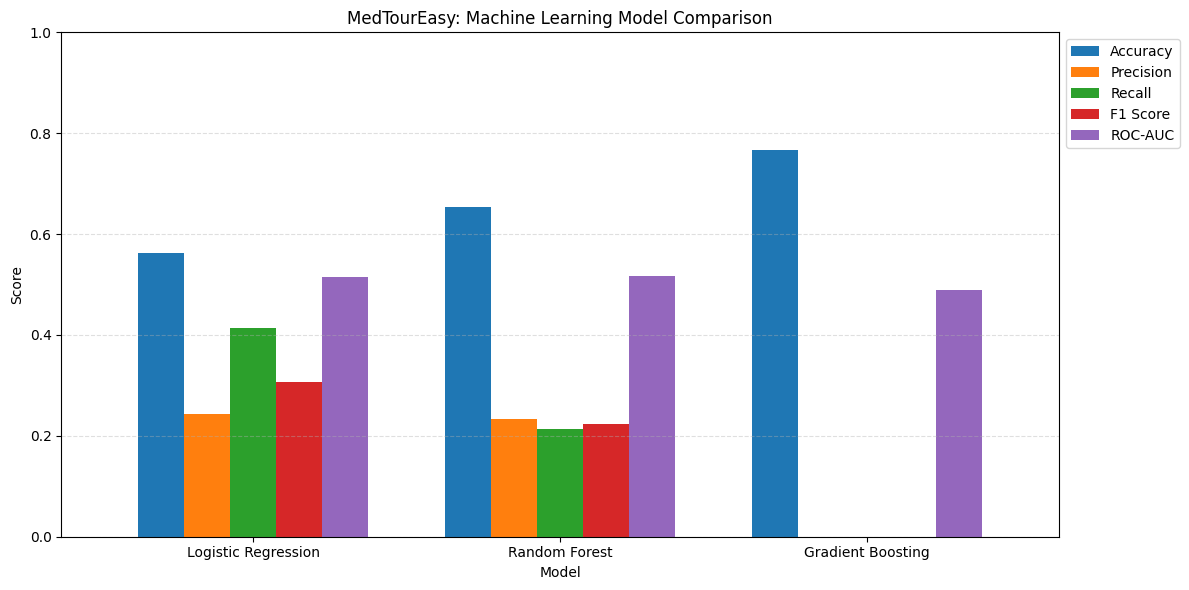

In [31]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

comparison_plot = model_comparison.set_index('Model')[metrics]

ax = comparison_plot.plot(
    kind='bar',
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title('MedTourEasy: Machine Learning Model Comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

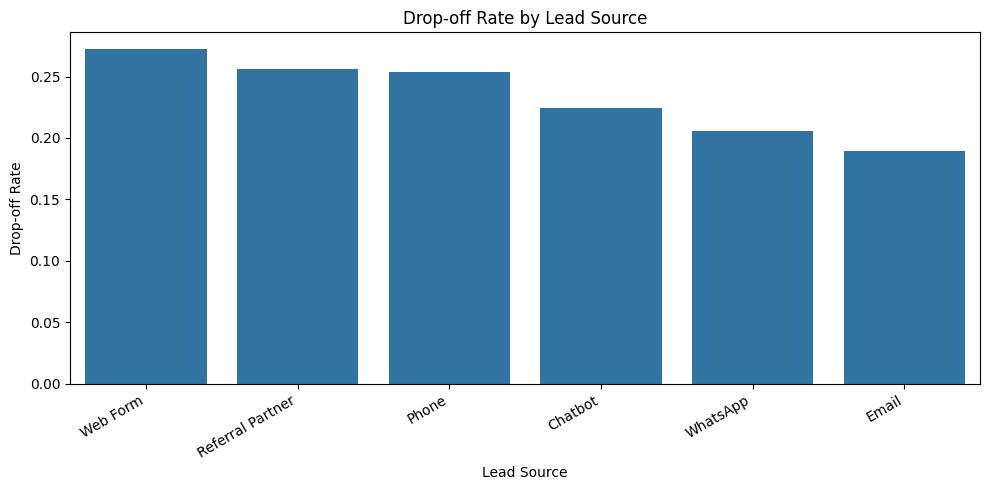

,Drop-off Rate
lead_source,
Web Form,0.272358
Referral Partner,0.256098
Phone,0.254098
Chatbot,0.224409
WhatsApp,0.205882
Email,0.189076


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert target column to numeric
patients_ml['drop_off_flag'] = pd.to_numeric(
    patients_ml['drop_off_flag'], errors='raise'
)

feature = 'lead_source'

dropoff_rates = (
    patients_ml.groupby(feature, observed=True)['drop_off_flag']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=dropoff_rates.index, y=dropoff_rates.values)

plt.title('Drop-off Rate by Lead Source')
plt.xlabel('Lead Source')
plt.ylabel('Drop-off Rate')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

display(dropoff_rates.to_frame('Drop-off Rate'))

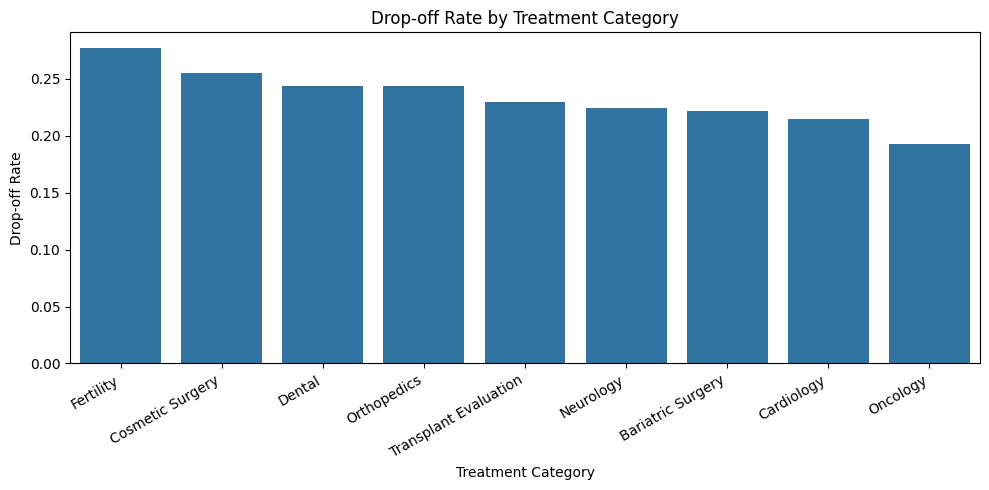

,Drop-off Rate
treatment_category,
Fertility,0.277108
Cosmetic Surgery,0.255556
Dental,0.243590
Orthopedics,0.243590
Transplant Evaluation,0.229814
Neurology,0.224138
Bariatric Surgery,0.222222
Cardiology,0.215190
Oncology,0.192513


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

feature = 'treatment_category'

dropoff_rates = (
    patients_ml.groupby(feature, observed=True)['drop_off_flag']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=dropoff_rates.index, y=dropoff_rates.values)

plt.title('Drop-off Rate by Treatment Category')
plt.xlabel('Treatment Category')
plt.ylabel('Drop-off Rate')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

display(dropoff_rates.to_frame('Drop-off Rate'))

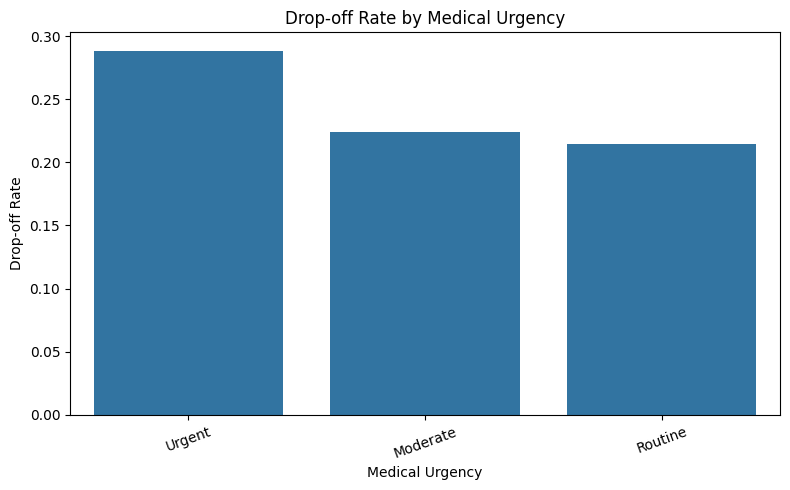

,Drop-off Rate
medical_urgency,
Urgent,0.288525
Moderate,0.223684
Routine,0.214651


In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

feature = 'medical_urgency'

dropoff_rates = (
    patients_ml.groupby(feature, observed=True)['drop_off_flag']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=dropoff_rates.index, y=dropoff_rates.values)

plt.title('Drop-off Rate by Medical Urgency')
plt.xlabel('Medical Urgency')
plt.ylabel('Drop-off Rate')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(dropoff_rates.to_frame('Drop-off Rate'))

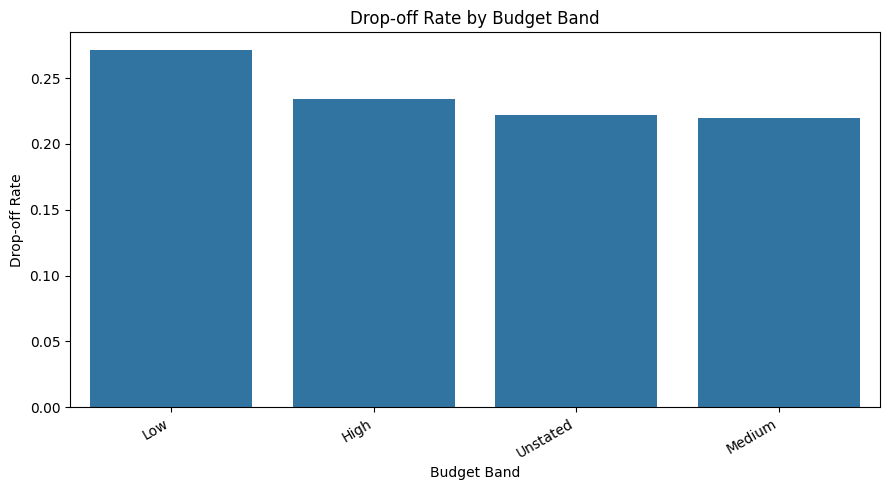

,Drop-off Rate
budget_band,
Low,0.271255
High,0.234469
Unstated,0.221719
Medium,0.219512


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

feature = 'budget_band'

dropoff_rates = (
    patients_ml.groupby(feature, observed=True)['drop_off_flag']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=dropoff_rates.index, y=dropoff_rates.values)

plt.title('Drop-off Rate by Budget Band')
plt.xlabel('Budget Band')
plt.ylabel('Drop-off Rate')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

display(dropoff_rates.to_frame('Drop-off Rate'))

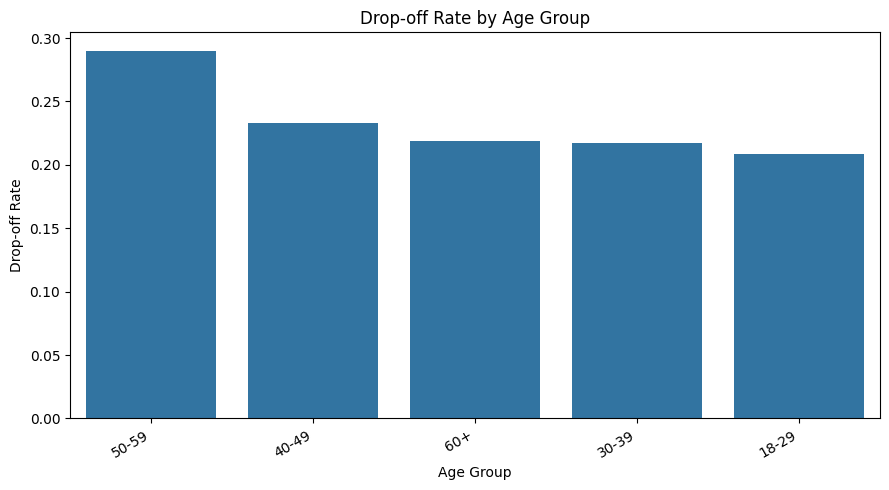

,Drop-off Rate
age_group,
50-59,0.290000
40-49,0.232639
60+,0.219136
30-39,0.216949
18-29,0.208191


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

feature = 'age_group'

dropoff_rates = (
    patients_ml.groupby(feature, observed=True)['drop_off_flag']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=dropoff_rates.index, y=dropoff_rates.values)

plt.title('Drop-off Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Drop-off Rate')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

display(dropoff_rates.to_frame('Drop-off Rate'))

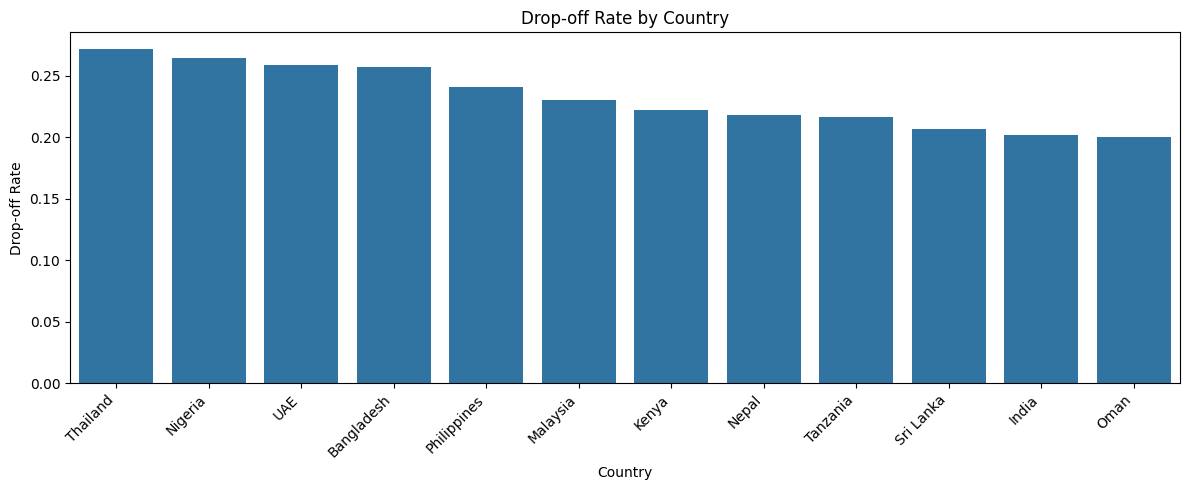

,Drop-off Rate,Patient Count
country,,
Thailand,0.271930,114
Nigeria,0.264957,117
UAE,0.258741,143
Bangladesh,0.257353,136
Philippines,0.241135,141
Malaysia,0.230769,130
Kenya,0.222222,126
Nepal,0.218045,133
Tanzania,0.216667,120


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

feature = 'country'

dropoff_rates = (
    patients_ml.groupby(feature, observed=True)['drop_off_flag']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=False)
)

plt.figure(figsize=(12, 5))
sns.barplot(x=dropoff_rates.index, y=dropoff_rates['mean'])

plt.title('Drop-off Rate by Country')
plt.xlabel('Country')
plt.ylabel('Drop-off Rate')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

display(dropoff_rates.rename(
    columns={'mean': 'Drop-off Rate', 'count': 'Patient Count'}
))

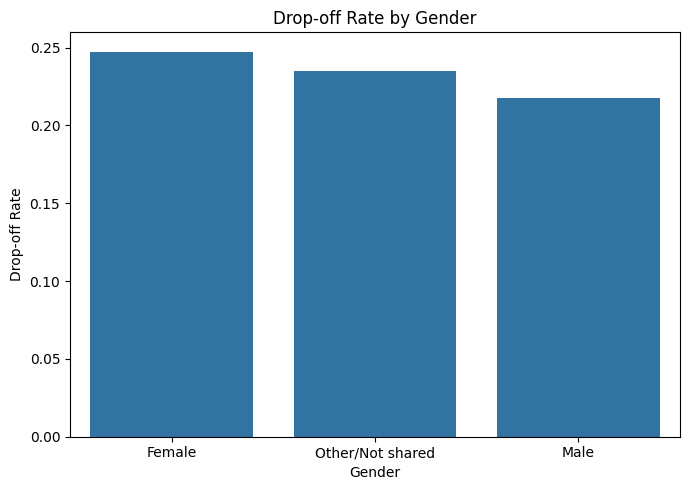

,Drop-off Rate,Patient Count
gender,,
Female,0.247444,489
Other/Not shared,0.235067,519
Male,0.217480,492


In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

feature = 'gender'

dropoff_rates = (
    patients_ml.groupby(feature, observed=True)['drop_off_flag']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=False)
)

plt.figure(figsize=(7, 5))
sns.barplot(x=dropoff_rates.index, y=dropoff_rates['mean'])

plt.title('Drop-off Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Drop-off Rate')
plt.tight_layout()
plt.show()

display(dropoff_rates.rename(
    columns={'mean': 'Drop-off Rate', 'count': 'Patient Count'}
))

In [40]:
features = [
    'lead_source',
    'treatment_category',
    'medical_urgency',
    'budget_band',
    'age_group',
    'country',
    'gender'
]

insights = []

for feature in features:
    summary = (
        patients_ml.groupby(feature, observed=True)['drop_off_flag']
        .agg(['mean', 'count'])
        .sort_values('mean', ascending=False)
    )

    insights.append({
        'Feature': feature,
        'Highest Drop-off Category': summary.index[0],
        'Highest Drop-off Rate': round(summary.iloc[0]['mean'] * 100, 2),
        'Patients in Category': int(summary.iloc[0]['count']),
        'Lowest Drop-off Category': summary.index[-1],
        'Lowest Drop-off Rate': round(summary.iloc[-1]['mean'] * 100, 2)
    })

business_insights = pd.DataFrame(insights)
display(business_insights)

,Feature,Highest Drop-off Category,Highest Drop-off Rate,Patients in Category,Lowest Drop-off Category,Lowest Drop-off Rate
0,lead_source,Web Form,27.24,246,Email,18.91
1,treatment_category,Fertility,27.71,166,Oncology,19.25
2,medical_urgency,Urgent,28.85,305,Routine,21.47
3,budget_band,Low,27.13,247,Medium,21.95
4,age_group,50-59,29.00,300,18-29,20.82
5,country,Thailand,27.19,114,Oman,20.00
6,gender,Female,24.74,489,Male,21.75


In [41]:
# Check recorded drop-off labels against treatment completion

label_check = pd.crosstab(
    patients_ml['drop_off_flag'],
    patients_ml['treatment_completed'],
    margins=True
)

display(label_check)

print("\nDrop-off flag distribution:")
display(patients_ml['drop_off_flag'].value_counts(dropna=False))

print("\nTreatment completion distribution:")
display(patients_ml['treatment_completed'].value_counts(dropna=False))

treatment_completed,0,1,All
drop_off_flag,,,
0,596,554,1150
1,350,0,350
All,946,554,1500



Drop-off flag distribution:


,count
drop_off_flag,
0,1150
1,350



Treatment completion distribution:


,count
treatment_completed,
0,946
1,554


In [42]:
unresolved = patients_ml[
    (patients_ml['drop_off_flag'] == 0) &
    (patients_ml['treatment_completed'] == 0)
]

stage_summary = (
    unresolved['current_stage']
    .value_counts()
    .rename_axis('Current Stage')
    .reset_index(name='Patient Count')
)

display(stage_summary)

,Current Stage,Patient Count


In [43]:
stage_validation = pd.crosstab(
    patients_ml['current_stage'],
    [
        patients_ml['drop_off_flag'],
        patients_ml['treatment_completed']
    ],
    margins=True
)

display(stage_validation)

drop_off_flag          0         1   All
treatment_completed    0    1    0      
current_stage                           
Consultation         178    0  117   295
First Response       253    0  162   415
Follow-up              0  312    0   312
Quote Shared         165    0   71   236
Treatment Completed    0  242    0   242
All                  596  554  350  1500

In [45]:
# Convert outcome columns to numeric safely
patients_ml['treatment_completed'] = pd.to_numeric(
    patients_ml['treatment_completed'], errors='raise'
)

patients_ml['drop_off_flag'] = pd.to_numeric(
    patients_ml['drop_off_flag'], errors='raise'
)

# Summarize outcomes by current stage
stage_completion = (
    patients_ml.groupby('current_stage', observed=True)
    .agg(
        Patient_Count=('current_stage', 'size'),
        Completed_Treatments=('treatment_completed', 'sum'),
        Drop_offs=('drop_off_flag', 'sum')
    )
)

stage_completion['Completion_Rate_%'] = (
    stage_completion['Completed_Treatments']
    / stage_completion['Patient_Count'] * 100
).round(2)

display(stage_completion)

,Patient_Count,Completed_Treatments,Drop_offs,Completion_Rate_%
current_stage,,,,
Consultation,295,0,117,0.0
First Response,415,0,162,0.0
Follow-up,312,312,0,100.0
Quote Shared,236,0,71,0.0
Treatment Completed,242,242,0,100.0


In [46]:
stage_label_check = (
    patients_ml.groupby('current_stage', observed=True)
    .agg(
        Patient_Count=('current_stage', 'size'),
        Unique_Dropoff_Labels=('drop_off_flag', 'nunique'),
        Unique_Completion_Labels=('treatment_completed', 'nunique')
    )
)

display(stage_label_check)

,Patient_Count,Unique_Dropoff_Labels,Unique_Completion_Labels
current_stage,,,
Consultation,295,2,1
First Response,415,2,1
Follow-up,312,1,1
Quote Shared,236,2,1
Treatment Completed,242,1,1


,Feature,Importance
37,budget_band_Medium,0.046580
35,budget_band_High,0.045559
40,medical_urgency_Routine,0.042439
18,gender_Male,0.042110
19,gender_Other/Not shared,0.040923
15,age_group_50-59,0.040651
39,medical_urgency_Moderate,0.039588
17,gender_Female,0.035541
34,lead_source_WhatsApp,0.034478
30,lead_source_Email,0.033307


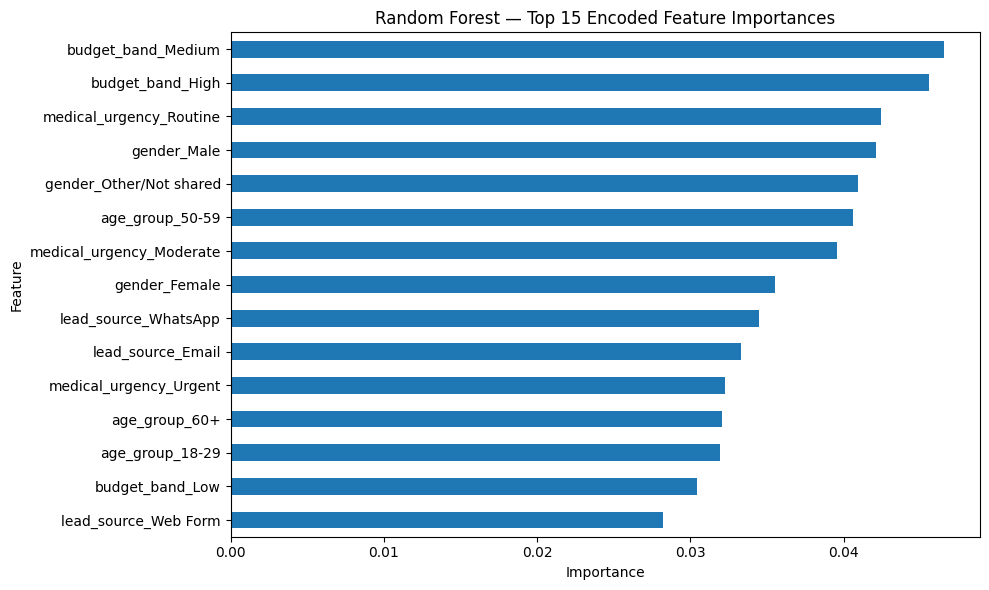

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

rf_model = rf_inquiry_pipeline.named_steps['model']
encoder = (
    rf_inquiry_pipeline.named_steps['preprocessor']
    .named_transformers_['cat']
    .named_steps['encoder']
)

encoded_names = encoder.get_feature_names_out(inquiry_features)
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': encoded_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

display(importance_df.head(15))

importance_df.head(15).sort_values('Importance').plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(10, 6),
    legend=False
)

plt.title('Random Forest — Top 15 Encoded Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

,Feature,Importance_Mean,Importance_STD
1,age_group,0.0250,0.0232
2,gender,0.0121,0.0164
5,budget_band,0.0104,0.0184
6,medical_urgency,0.0054,0.0235
3,treatment_category,-0.0139,0.0145
4,lead_source,-0.0158,0.0252
0,country,-0.0179,0.0091


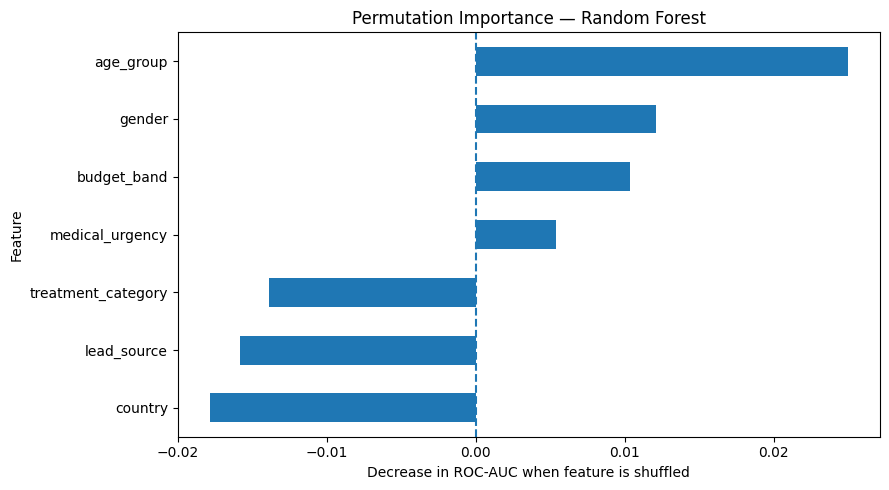

In [48]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

perm_result = permutation_importance(
    rf_inquiry_pipeline,
    X_test_inquiry,
    y_test_inquiry,
    scoring='roc_auc',
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': X_test_inquiry.columns,
    'Importance_Mean': perm_result.importances_mean,
    'Importance_STD': perm_result.importances_std
}).sort_values('Importance_Mean', ascending=False)

display(permutation_df.round(4))

permutation_df.sort_values('Importance_Mean').plot(
    x='Feature',
    y='Importance_Mean',
    kind='barh',
    figsize=(9, 5),
    legend=False
)

plt.axvline(0, linestyle='--')
plt.title('Permutation Importance — Random Forest')
plt.xlabel('Decrease in ROC-AUC when feature is shuffled')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [49]:
display(
    patients_ml.groupby(
        ['drop_off_flag', 'treatment_completed'],
        dropna=False
    ).size().unstack(fill_value=0)
)

treatment_completed,0,1
drop_off_flag,,
0,596,554
1,350,0


In [50]:
unresolved_patients = patients_ml[
    (patients_ml['drop_off_flag'] == 0) &
    (patients_ml['treatment_completed'] == 0)
]

display(
    unresolved_patients['current_stage']
    .value_counts()
    .rename_axis('Current_Stage')
    .reset_index(name='Patient_Count')
)

,Current_Stage,Patient_Count
0,First Response,253
1,Consultation,178
2,Quote Shared,165


In [51]:
display(
    pd.crosstab(
        patients_ml['current_stage'],
        patients_ml['drop_off_flag'],
        margins=True
    )
)

drop_off_flag,0,1,All
current_stage,,,
Consultation,178,117,295
First Response,253,162,415
Follow-up,312,0,312
Quote Shared,165,71,236
Treatment Completed,242,0,242
All,1150,350,1500


In [52]:
print("DATAFRAMES AVAILABLE:")
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

print("\nDATABASE TABLES:")
display(pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
))

DATAFRAMES AVAILABLE:
dictionary: (67, 4)
patients: (1500, 26)
patients_ml: (1500, 26)
X_inquiry: (1500, 7)
X_train_inquiry: (1200, 7)
X_test_inquiry: (300, 7)
model_comparison: (3, 6)
comparison_plot: (3, 5)
dropoff_rates: (3, 2)
summary: (3, 2)
business_insights: (7, 6)
label_check: (3, 3)
unresolved: (0, 26)
stage_summary: (0, 2)
stage_validation: (6, 4)
stage_completion: (5, 4)
stage_label_check: (5, 3)
importance_df: (42, 2)
permutation_df: (7, 3)
unresolved_patients: (596, 26)

DATABASE TABLES:


,name
0,patient_journey
1,provider_master
2,communication_logs
3,treatment_outcomes
4,country_reference


In [53]:
providers = pd.read_sql_query(
    "SELECT * FROM provider_master",
    conn
)

print("Provider dataset shape:", providers.shape)
print("\nColumns:")
print(providers.columns.tolist())

display(providers.head(5))

Provider dataset shape: (30, 14)

Columns:
['provider_id', 'provider_name', 'region', 'country', 'specialty_area', 'bed_capacity', 'international_patient_desk', 'avg_first_response_hours', 'historical_consultation_conversion_rate', 'historical_treatment_conversion_rate', 'follow_up_completion_rate', 'satisfaction_index', 'pricing_tier', 'contract_status']


,provider_id,provider_name,region,country,specialty_area,bed_capacity,international_patient_desk,avg_first_response_hours,historical_consultation_conversion_rate,historical_treatment_conversion_rate,follow_up_completion_rate,satisfaction_index,pricing_tier,contract_status
0,PVD-001,MTE Partner Hospital 01,South Asia,UAE,Cardiology,350,Yes,12.8,0.312,0.07,0.74,72.5,Economy,Active
1,PVD-002,MTE Partner Hospital 02,Middle East,Oman,Fertility,350,No,16.3,0.421,0.236,0.785,75.5,Economy,Active
2,PVD-003,MTE Partner Hospital 03,West Africa,Nigeria,Dental,80,Yes,12.3,0.35,0.288,0.543,84.2,Economy,Pilot
3,PVD-004,MTE Partner Hospital 04,Southeast Asia,Sri Lanka,Orthopedics,150,Yes,16.9,0.396,0.071,0.476,84.8,Economy,Active
4,PVD-005,MTE Partner Hospital 05,East Africa,Tanzania,Orthopedics,150,No,20.4,0.31,0.127,0.498,63.2,Standard,Active


In [54]:
provider_analysis = providers.copy()

provider_analysis['response_speed_score'] = (
    provider_analysis['avg_first_response_hours']
    .rank(ascending=True, pct=True)
)

provider_analysis['provider_performance_rank'] = (
    provider_analysis['historical_treatment_conversion_rate']
    .rank(ascending=False, method='min')
    .astype(int)
)

display(
    provider_analysis[
        [
            'provider_name',
            'country',
            'specialty_area',
            'historical_consultation_conversion_rate',
            'historical_treatment_conversion_rate',
            'follow_up_completion_rate',
            'avg_first_response_hours',
            'satisfaction_index',
            'contract_status',
            'provider_performance_rank'
        ]
    ].sort_values('provider_performance_rank')
    .round(3)
    .reset_index(drop=True)
)

,provider_name,country,specialty_area,historical_consultation_conversion_rate,historical_treatment_conversion_rate,follow_up_completion_rate,avg_first_response_hours,satisfaction_index,contract_status,provider_performance_rank
0,MTE Partner Hospital 30,Bangladesh,Dental,0.53,0.378,0.552,15.5,79.1,Active,1
1,MTE Partner Hospital 20,India,Transplant Evaluation,0.546,0.356,0.666,1.2,66.7,Active,2
2,MTE Partner Hospital 06,Nepal,Oncology,0.402,0.355,0.576,16.0,71.5,Active,3
3,MTE Partner Hospital 19,Nepal,Transplant Evaluation,0.83,0.34,0.808,13.0,96,Active,4
4,MTE Partner Hospital 07,Nigeria,Cardiology,0.724,0.31,0.386,13.2,80.4,Pilot,5
5,MTE Partner Hospital 03,Nigeria,Dental,0.35,0.288,0.543,12.3,84.2,Pilot,6
6,MTE Partner Hospital 17,Tanzania,Transplant Evaluation,0.562,0.281,0.454,13.3,87.4,Active,7
7,MTE Partner Hospital 28,UAE,Cosmetic Surgery,0.477,0.278,0.743,12.8,85.4,Pilot,8
8,MTE Partner Hospital 26,Kenya,Bariatric Surgery,0.439,0.263,0.562,15.6,92.3,Active,9
9,MTE Partner Hospital 18,Bangladesh,Cardiology,0.497,0.252,0.742,16.1,71.4,Active,10


In [55]:
print("Patient journey columns:")
print(patients_ml.columns.tolist())

print("\nProvider master columns:")
print(providers.columns.tolist())

common_columns = sorted(
    set(patients_ml.columns).intersection(providers.columns)
)

print("\nCommon columns:")
print(common_columns)

Patient journey columns:
['patient_id', 'inquiry_date', 'country', 'age_group', 'gender', 'treatment_category', 'provider_id', 'lead_source', 'coordinator_id', 'budget_band', 'medical_urgency', 'intent_score', 'response_time_hours', 'engagement_score', 'consultation_booked', 'quote_shared', 'treatment_completed', 'follow_up_completed', 'current_stage', 'drop_off_flag', 'drop_off_stage', 'reason_for_drop_off', 'estimated_case_value_inr', 'actual_revenue_inr', 'service_cost_inr', 'satisfaction_score']

Provider master columns:
['provider_id', 'provider_name', 'region', 'country', 'specialty_area', 'bed_capacity', 'international_patient_desk', 'avg_first_response_hours', 'historical_consultation_conversion_rate', 'historical_treatment_conversion_rate', 'follow_up_completion_rate', 'satisfaction_index', 'pricing_tier', 'contract_status']

Common columns:
['country', 'provider_id']


In [59]:
import pandas as pd

provider_patient_analysis = patients_ml.merge(
    providers,
    on='provider_id',
    how='left',
    suffixes=('_patient', '_provider')
)

# Convert all metric columns to numeric
numeric_columns = [
    'consultation_booked',
    'quote_shared',
    'treatment_completed',
    'follow_up_completed',
    'drop_off_flag',
    'actual_revenue_inr',
    'satisfaction_score'
]

for col in numeric_columns:
    provider_patient_analysis[col] = pd.to_numeric(
        provider_patient_analysis[col], errors='coerce'
    )

provider_performance = (
    provider_patient_analysis
    .groupby(['provider_id', 'provider_name'], dropna=False)
    .agg(
        patient_volume=('patient_id', 'nunique'),
        consultation_rate=('consultation_booked', 'mean'),
        quote_rate=('quote_shared', 'mean'),
        treatment_completion_rate=('treatment_completed', 'mean'),
        follow_up_completion_rate=('follow_up_completed', 'mean'),
        drop_off_rate=('drop_off_flag', 'mean'),
        actual_revenue_inr=('actual_revenue_inr', 'sum'),
        average_satisfaction=('satisfaction_score', 'mean')
    )
    .reset_index()
    .sort_values('treatment_completion_rate', ascending=False)
)

display(provider_performance.round(3))

,provider_id,provider_name,patient_volume,consultation_rate,quote_rate,treatment_completion_rate,follow_up_completion_rate,drop_off_rate,actual_revenue_inr,average_satisfaction
19,PVD-020,MTE Partner Hospital 20,55,0.891,0.564,0.527,0.382,0.145,13379748,7.962
6,PVD-007,MTE Partner Hospital 07,50,0.720,0.500,0.520,0.240,0.180,12239804,7.492
7,PVD-008,MTE Partner Hospital 08,55,0.818,0.491,0.509,0.145,0.127,13774849,8.225
0,PVD-001,MTE Partner Hospital 01,55,0.727,0.436,0.473,0.364,0.182,12202774,7.454
10,PVD-011,MTE Partner Hospital 11,49,0.755,0.408,0.469,0.224,0.204,8513562,7.804
16,PVD-017,MTE Partner Hospital 17,43,0.744,0.419,0.465,0.093,0.256,8227215,7.780
14,PVD-015,MTE Partner Hospital 15,56,0.679,0.393,0.464,0.250,0.196,13251837,8.223
2,PVD-003,MTE Partner Hospital 03,59,0.712,0.424,0.441,0.288,0.153,10342004,7.296
21,PVD-022,MTE Partner Hospital 22,47,0.660,0.447,0.426,0.170,0.128,8746069,7.335
20,PVD-021,MTE Partner Hospital 21,51,0.765,0.451,0.412,0.196,0.196,9162836,7.976


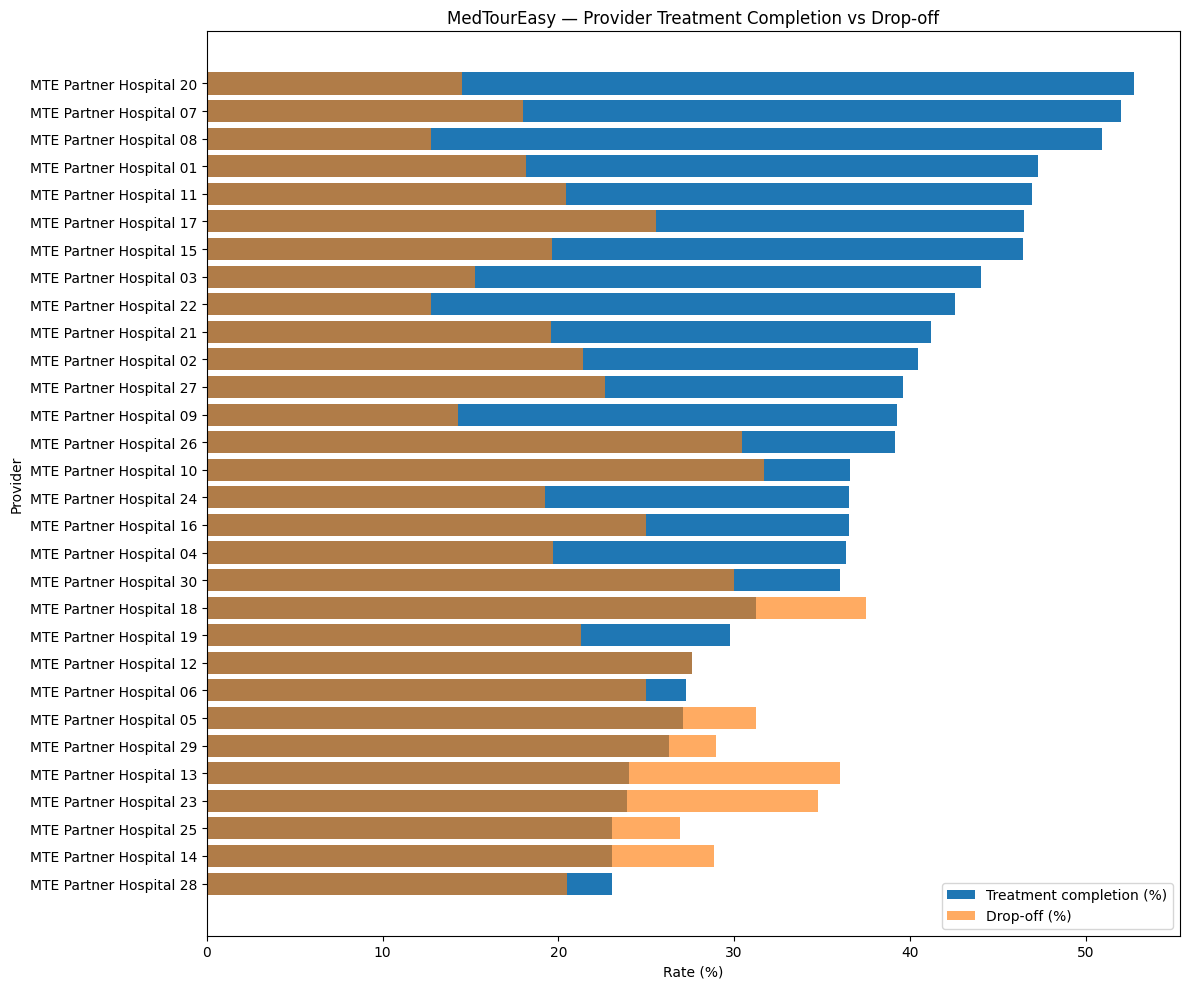

In [60]:
import matplotlib.pyplot as plt

chart_data = provider_performance.sort_values(
    'treatment_completion_rate', ascending=True
)

plt.figure(figsize=(12, 10))

plt.barh(
    chart_data['provider_name'],
    chart_data['treatment_completion_rate'] * 100,
    label='Treatment completion (%)'
)

plt.barh(
    chart_data['provider_name'],
    chart_data['drop_off_rate'] * 100,
    alpha=0.65,
    label='Drop-off (%)'
)

plt.xlabel('Rate (%)')
plt.ylabel('Provider')
plt.title('MedTourEasy — Provider Treatment Completion vs Drop-off')
plt.legend()
plt.tight_layout()
plt.show()

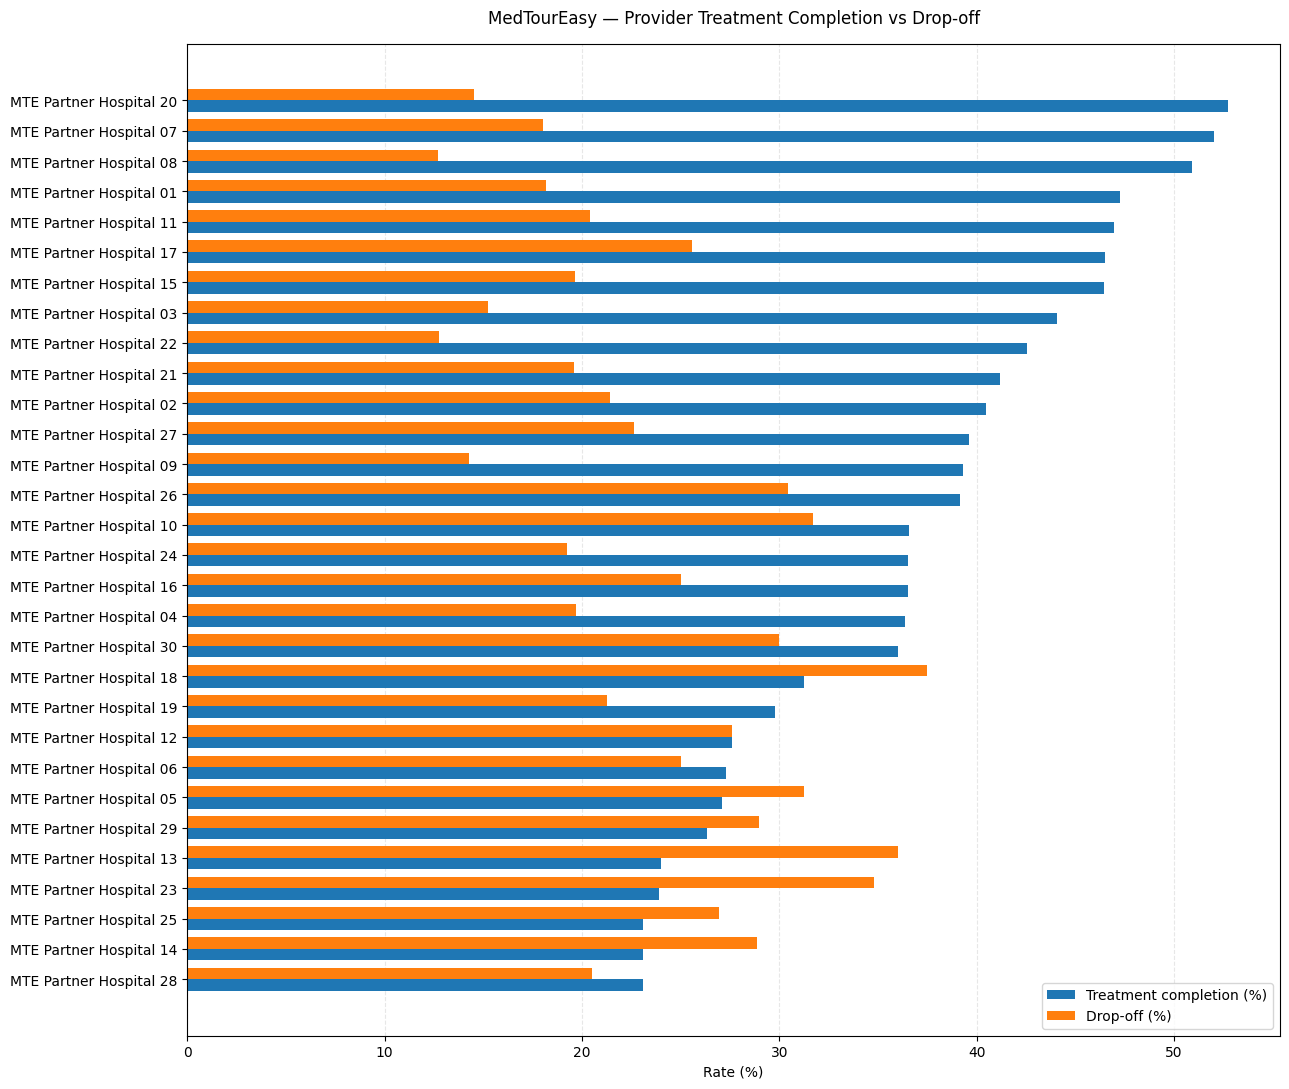

In [61]:
import matplotlib.pyplot as plt
import numpy as np

chart_data = provider_performance.sort_values(
    'treatment_completion_rate', ascending=True
).reset_index(drop=True)

y = np.arange(len(chart_data))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(13, 11))

ax.barh(
    y - bar_height / 2,
    chart_data['treatment_completion_rate'] * 100,
    bar_height,
    label='Treatment completion (%)'
)

ax.barh(
    y + bar_height / 2,
    chart_data['drop_off_rate'] * 100,
    bar_height,
    label='Drop-off (%)'
)

ax.set_yticks(y)
ax.set_yticklabels(chart_data['provider_name'])
ax.set_xlabel('Rate (%)')
ax.set_title(
    'MedTourEasy — Provider Treatment Completion vs Drop-off',
    pad=15
)
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [62]:
completion_median = provider_performance[
    'treatment_completion_rate'
].median()

dropoff_median = provider_performance[
    'drop_off_rate'
].median()

provider_improvement = provider_performance[
    (provider_performance['treatment_completion_rate'] < completion_median) &
    (provider_performance['drop_off_rate'] > dropoff_median)
].copy()

provider_improvement = provider_improvement[
    [
        'provider_name',
        'patient_volume',
        'treatment_completion_rate',
        'drop_off_rate',
        'follow_up_completion_rate',
        'average_satisfaction',
        'actual_revenue_inr'
    ]
].sort_values(
    ['drop_off_rate', 'treatment_completion_rate'],
    ascending=[False, True]
)

print("Providers flagged for review:", len(provider_improvement))
display(provider_improvement.round(3))

Providers flagged for review: 11


,provider_name,patient_volume,treatment_completion_rate,drop_off_rate,follow_up_completion_rate,average_satisfaction,actual_revenue_inr
17,MTE Partner Hospital 18,48,0.312,0.375,0.208,7.427,7651836
12,MTE Partner Hospital 13,50,0.240,0.360,0.120,7.033,5140654
22,MTE Partner Hospital 23,46,0.239,0.348,0.087,7.273,3672695
4,MTE Partner Hospital 05,48,0.271,0.312,0.104,7.115,5982422
29,MTE Partner Hospital 30,50,0.360,0.300,0.220,7.511,7720112
28,MTE Partner Hospital 29,38,0.263,0.289,0.184,6.850,5312950
13,MTE Partner Hospital 14,52,0.231,0.288,0.096,7.350,5285592
11,MTE Partner Hospital 12,58,0.276,0.276,0.121,7.888,6489310
24,MTE Partner Hospital 25,52,0.231,0.269,0.096,7.392,5949875
5,MTE Partner Hospital 06,44,0.273,0.250,0.114,7.517,6526165


In [63]:
def recommend_action(row):
    actions = []

    if row['follow_up_completion_rate'] < 0.15:
        actions.append(
            "Audit follow-up workflow; assign case owners and escalation reminders"
        )
    elif row['follow_up_completion_rate'] < 0.25:
        actions.append(
            "Review follow-up delays and introduce scheduled patient check-ins"
        )

    if row['drop_off_rate'] >= 0.30:
        actions.append(
            "Review drop-off reasons and contact unresolved patients"
        )

    if row['average_satisfaction'] < 7.2:
        actions.append(
            "Review patient feedback and service complaints"
        )

    if row['treatment_completion_rate'] < completion_median:
        actions.append(
            "Audit consultation-to-quote and quote-to-treatment progression"
        )

    return "; ".join(actions) if actions else "Continue monitoring"

provider_improvement['recommended_actions'] = (
    provider_improvement.apply(recommend_action, axis=1)
)

display(
    provider_improvement[
        [
            'provider_name',
            'patient_volume',
            'treatment_completion_rate',
            'drop_off_rate',
            'follow_up_completion_rate',
            'recommended_actions'
        ]
    ].reset_index(drop=True)
)

,provider_name,patient_volume,treatment_completion_rate,drop_off_rate,follow_up_completion_rate,recommended_actions
0,MTE Partner Hospital 18,48,0.312500,0.375000,0.208333,Review follow-up delays and introduce schedule...
1,MTE Partner Hospital 13,50,0.240000,0.360000,0.120000,Audit follow-up workflow; assign case owners a...
2,MTE Partner Hospital 23,46,0.239130,0.347826,0.086957,Audit follow-up workflow; assign case owners a...
3,MTE Partner Hospital 05,48,0.270833,0.312500,0.104167,Audit follow-up workflow; assign case owners a...
4,MTE Partner Hospital 30,50,0.360000,0.300000,0.220000,Review follow-up delays and introduce schedule...
5,MTE Partner Hospital 29,38,0.263158,0.289474,0.184211,Review follow-up delays and introduce schedule...
6,MTE Partner Hospital 14,52,0.230769,0.288462,0.096154,Audit follow-up workflow; assign case owners a...
7,MTE Partner Hospital 12,58,0.275862,0.275862,0.120690,Audit follow-up workflow; assign case owners a...
8,MTE Partner Hospital 25,52,0.230769,0.269231,0.096154,Audit follow-up workflow; assign case owners a...
9,MTE Partner Hospital 06,44,0.272727,0.250000,0.113636,Audit follow-up workflow; assign case owners a...


In [64]:
import os

output_dir = '/content/drive/MyDrive/MedTourEasy_Outputs'
os.makedirs(output_dir, exist_ok=True)

provider_performance.to_csv(
    f'{output_dir}/provider_performance.csv',
    index=False
)

provider_improvement.to_csv(
    f'{output_dir}/provider_improvement_recommendations.csv',
    index=False
)

print("Provider analysis files saved successfully:")
print(output_dir)
print("\n1. provider_performance.csv")
print("2. provider_improvement_recommendations.csv")

Provider analysis files saved successfully:
/content/drive/MyDrive/MedTourEasy_Outputs

1. provider_performance.csv
2. provider_improvement_recommendations.csv


In [65]:
import os

output_dir = '/content/drive/MyDrive/MedTourEasy_Outputs'

print("Files currently saved:")
for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

Files currently saved:
- provider_improvement_recommendations.csv
- provider_performance.csv


In [67]:
patient_outputs = [
    'model_comparison',
    'dropoff_rates',
    'summary',
    'business_insights',
    'stage_summary',
    'stage_validation',
    'stage_completion',
    'permutation_df'
]

for name in patient_outputs:
    obj = globals().get(name)
    if obj is not None:
        print(f"{name}: {obj.shape}")
    else:
        print(f"{name}: not available")

model_comparison: (3, 6)
dropoff_rates: (3, 2)
summary: (3, 2)
business_insights: (7, 6)
stage_summary: (0, 2)
stage_validation: (6, 4)
stage_completion: (5, 4)
permutation_df: (7, 3)


In [68]:
import os

output_dir = '/content/drive/MyDrive/MedTourEasy_Outputs'
os.makedirs(output_dir, exist_ok=True)

outputs_to_save = {
    'model_comparison': model_comparison,
    'dropoff_rates': dropoff_rates,
    'patient_summary': summary,
    'business_insights': business_insights,
    'stage_validation': stage_validation,
    'stage_completion': stage_completion,
    'permutation_importance': permutation_df
}

for filename, dataframe in outputs_to_save.items():
    dataframe.to_csv(
        os.path.join(output_dir, f'{filename}.csv'),
        index=False
    )

print("Saved patient-analysis outputs:")
for filename in outputs_to_save:
    print(f"- {filename}.csv")

print("\nTotal CSV files:", len(os.listdir(output_dir)))

Saved patient-analysis outputs:
- model_comparison.csv
- dropoff_rates.csv
- patient_summary.csv
- business_insights.csv
- stage_validation.csv
- stage_completion.csv
- permutation_importance.csv

Total CSV files: 9


In [69]:
import os

output_dir = '/content/drive/MyDrive/MedTourEasy_Outputs'

for filename in sorted(os.listdir(output_dir)):
    filepath = os.path.join(output_dir, filename)
    print(f'{filename} — {os.path.getsize(filepath):,} bytes')

business_insights.csv — 415 bytes
dropoff_rates.csv — 81 bytes
model_comparison.csv — 185 bytes
patient_summary.csv — 81 bytes
permutation_importance.csv — 419 bytes
provider_improvement_recommendations.csv — 3,026 bytes
provider_performance.csv — 4,496 bytes
stage_completion.csv — 136 bytes
stage_validation.csv — 99 bytes


model_comparison: (3, 6)
dropoff_rates: (3, 2)
summary: (3, 2)
business_insights: (7, 6)
stage_summary: (0, 2)
stage_validation: (6, 4)
stage_completion: (5, 4)
permutation_df: (7, 3)
